In [1]:
import datetime as dt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import requests
import re
import pickle 
import pickle as pk
import keras
import tensorflow as tf
import os

from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

from keras import layers
from keras.layers import RepeatVector
from keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard
from keras.models import Sequential, Model, load_model
from keras.layers import Input, Dense, Activation, Flatten, Dropout
from keras.layers import SimpleRNN, GRU
from keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Input, LSTM, RepeatVector, TimeDistributed
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest

from torchdiffeq import odeint
import torchcde  

from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, accuracy_score

import plotly.graph_objs as go

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp: 
        return pickle.load(inp)

In [34]:
### Visualization 2020 to 2023

df = pd.read_csv("./CSV data/GT/GT_final.csv")
df.head()

start_date = '2020-01-01 00:00:00'
num_rows = len(df)
date_range = pd.date_range(start=start_date, periods=num_rows, freq='H')

df['date'] = date_range
df.to_csv("./CSV data/GT/GT_final_date.csv", index = False)


/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_97266/832067052.py:8: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  date_range = pd.date_range(start=start_date, periods=num_rows, freq='H')


In [35]:
df = pd.read_csv("./CSV data/GT/GT_final_date.csv")

In [2]:
### spike 처리 

date = df['date']
df = df[df.iloc[:, :-1] < 300]
df = df[df.iloc[:, :-1] > -300]
df['date'] = date

NameError: name 'df' is not defined

### Neural ODE

In [2]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super(SinusoidalTimeEmbedding, self).__init__()
        self.original_embedding_dim = embedding_dim
        if embedding_dim % 2 != 0:
            embedding_dim += 1
        self.embedding_dim = embedding_dim

    def forward(self, time_steps):
        device = time_steps.device
        batch_size, seq_len = time_steps.size()
        pe = torch.zeros(batch_size, seq_len, self.embedding_dim).to(device)
        position = time_steps.unsqueeze(-1)
        div_term = torch.exp(torch.arange(0, self.embedding_dim, 2, dtype=torch.float32).to(device) *
                             -(np.log(10000.0) / self.embedding_dim))
        pe[..., 0::2] = torch.sin(position * div_term)
        pe[..., 1::2] = torch.cos(position * div_term)
        return pe[..., :self.original_embedding_dim]

class ODEF(nn.Module):
    def __init__(self, hidden_dim):
        super(ODEF, self).__init__()
        self.linear1 = nn.Linear(hidden_dim, hidden_dim*2)
        self.bn1 = nn.BatchNorm1d(hidden_dim*2)
        self.linear2 = nn.Linear(hidden_dim*2, hidden_dim*2)
        self.bn2 = nn.BatchNorm1d(hidden_dim*2)
        self.linear3 = nn.Linear(hidden_dim*2, hidden_dim)
        self.dropout = nn.Dropout(0.1) # Dropout 약간 줄임

    def forward(self, t, h):
        batch_size = h.size(0)
        h = self.linear1(h)
        bn1_input = h.view(-1, self.linear1.out_features)
        if bn1_input.shape[0] > 1: h = self.bn1(bn1_input).view(batch_size, -1)
        h = F.relu(h)
        h = self.dropout(h)
        h = self.linear2(h)
        bn2_input = h.view(-1, self.linear2.out_features)
        if bn2_input.shape[0] > 1: h = self.bn2(bn2_input).view(batch_size, -1)
        h = F.relu(h)
        h = self.dropout(h)
        return self.linear3(h)

class LatentODEEncoder(nn.Module):
    """Latent ODE Encoder with Variational Inference"""
    def __init__(self, input_dim, hidden_dim, latent_dim): # latent_dim 추가
        super(LatentODEEncoder, self).__init__()
        self.hidden_dim = hidden_dim
        self.latent_dim = latent_dim # 실제 사용할 잠재 변수 차원
        # 초기 입력을 받아 mu와 logvar 계산
        self.initial_encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(hidden_dim // 2, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim // 2, latent_dim)
        self.odefunc = ODEF(latent_dim) 

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x, time_steps):
        # 1. 첫 시점 데이터로 mu, logvar 계산
        initial_features = self.initial_encoder(x[:, 0, :])
        mu = self.fc_mu(initial_features)         # [batch, latent_dim]
        logvar = self.fc_logvar(initial_features) # [batch, latent_dim]

        # 2. Reparameterization Trick으로 z0 샘플링
        z0 = self.reparameterize(mu, logvar)      # [batch, latent_dim]

        # 3. odeint 사용 준비
        t = time_steps[0]

        # 4. 샘플링된 z0로 ODE 풀기
        z_t = odeint(self.odefunc, z0, t, method='dopri5') # [seq_len, batch, latent_dim]

        # 5. 결과 반환 (mu, logvar 추가)
        return z_t.permute(1, 0, 2), mu, logvar # [batch, seq, latent], [batch, latent], [batch, latent]

class ODEDecoder(nn.Module):
    """Probabilistic ODE Decoder"""
    def __init__(self, latent_dim, output_dim, hidden_dim_ode): # latent_dim 사용
        super(ODEDecoder, self).__init__()
        # ODE 함수는 latent_dim 사용
        self.odefunc = ODEF(latent_dim) # ODEF의 hidden_dim을 latent_dim으로
        # 출력을 mu와 logvar로 분리
        self.output_proj = nn.Linear(latent_dim, output_dim * 2) # mu + logvar
        self.output_dim = output_dim

    def forward(self, z0, time_steps):
        batch_size, seq_len = time_steps.size()
        t = time_steps[0]
        z_t = odeint(self.odefunc, z0, t, method='dopri5') # [seq_len, batch, latent_dim]

        # 각 시간 스텝의 잠재 상태를 [mu, logvar]로 투영
        outputs_proj = self.output_proj(z_t) # [seq_len, batch, output_dim * 2]
        # mu와 logvar 분리
        recon_mu = outputs_proj[..., :self.output_dim]    # [seq_len, batch, output_dim]
        recon_logvar = outputs_proj[..., self.output_dim:] # [seq_len, batch, output_dim]

        # 차원 순서 변경
        return recon_mu.permute(1, 0, 2), recon_logvar.permute(1, 0, 2)

class ActNorm(nn.Module):
    """ Activation Normalization Layer """
    def __init__(self, num_features, eps=1e-6):
        super(ActNorm, self).__init__()
        self.num_features = num_features
        self.eps = eps
        # 학습 가능한 스케일(로그 스케일) 및 편향 파라미터
        self.log_scale = nn.Parameter(torch.zeros(1, num_features, 1)) # 채널 차원에 맞춤
        self.bias = nn.Parameter(torch.zeros(1, num_features, 1))
        self.initialized = False # 데이터 기반 초기화 플래그

    def _initialize(self, x):
        """ 첫 번째 배치 데이터로 파라미터 초기화 """
        if not self.training: # 평가 시에는 초기화 안 함
            return
        with torch.no_grad():
            # 입력 데이터의 평균과 표준편차 계산 (채널별)
            mean = torch.mean(x, dim=[0, 2], keepdim=True) # 배치와 시퀀스 차원에 대해 평균
            std = torch.std(x, dim=[0, 2], keepdim=True)
            # 파라미터 설정: scale = 1/std, bias = -mean/std
            self.log_scale.data.copy_(-torch.log(std + self.eps))
            self.bias.data.copy_(-mean / (std + self.eps))
            self.initialized = True
            print(f"ActNorm initialized with input shape {x.shape}")

    def forward(self, x, reverse=False):
        # x shape: [batch, features, seq_len] 또는 [batch, features]
        # 편의상 1D 입력 ([batch, features])을 가정하고 구현, 필요시 수정
        is_batched = x.dim() == 2
        if is_batched:
             x = x.unsqueeze(-1) # [batch, features, 1] 형태로 변환

        if not self.initialized and self.training:
            self._initialize(x)

        scale = torch.exp(self.log_scale)

        if not reverse:
            # 정방향: y = s*x + b
            y = scale * x + self.bias
            # 로그 자코비안 행렬식 계산
            log_det = self.log_scale.sum() * x.size(2) # seq_len 만큼 곱함 (또는 1 nếu is_batched)
        else:
            # 역방향: x = (y - b) / s
            y = (x - self.bias) * torch.exp(-self.log_scale)
            log_det = -self.log_scale.sum() * x.size(2)

        if is_batched:
            y = y.squeeze(-1) # 원래 형태로 복원

        return y, log_det

class Invertible1x1Conv(nn.Module):
    """ Invertible 1x1 Convolution (Permutation Enhancement) """
    def __init__(self, num_channels):
        super(Invertible1x1Conv, self).__init__()
        self.num_channels = num_channels
        # 직교 행렬(Orthogonal matrix)로 가중치 초기화
        W_init = np.random.randn(num_channels, num_channels)
        W_init = linalg.qr(W_init)[0].astype(np.float32) # QR 분해로 직교 행렬 생성
        self.register_parameter("weight", nn.Parameter(torch.tensor(W_init)))

    def forward(self, x, reverse=False):
        # x shape: [batch, channels] (Flow 내부에서는 보통 채널만 다룸)
        batch_size = x.size(0)
        W = self.weight

        if not reverse:
            # 정방향: y = Wx
            # 1x1 Conv는 채널 차원에 대한 행렬 곱과 동일
            y = F.linear(x, W)
            # 로그 자코비안 행렬식: log |det(W)|
            log_det = torch.slogdet(W)[1] * batch_size # 배치 크기만큼 곱함 (각 샘플에 대해 동일)
        else:
            # 역방향: x = W^{-1}y
            W_inv = torch.inverse(W)
            y = F.linear(x, W_inv)
            # 역행렬의 로그 행렬식: -log |det(W)|
            log_det = -torch.slogdet(W)[1] * batch_size

        return y, log_det

# AffineCoupling 클래스는 이전과 동일하게 사용 가능
class AffineCoupling(nn.Module):
    def __init__(self, dim):
        super().__init__()
        if dim % 2 != 0:
             raise ValueError(f"Flow input dim must be even, but got {dim}.")
        self.dim = dim
        hidden_layer_dim = dim
        self.scale_net = nn.Sequential(
            nn.Linear(dim // 2, hidden_layer_dim),
            nn.ReLU(),
            nn.Linear(hidden_layer_dim, dim // 2)
        )
        self.translate_net = nn.Sequential(
            nn.Linear(dim // 2, hidden_layer_dim),
            nn.ReLU(),
            nn.Linear(hidden_layer_dim, dim // 2)
        )
    def forward(self, x, reverse=False):
        x1, x2 = x.chunk(2, dim=1)
        s = self.scale_net(x1)
        t = self.translate_net(x1)
        if not reverse:
            y2 = x2 * torch.exp(s) + t
            log_det_jacobian = s.sum(dim=1)
        else:
            y2 = (x2 - t) * torch.exp(-s)
            log_det_jacobian = -s.sum(dim=1)
        return torch.cat([x1, y2], dim=1), log_det_jacobian

class SimpleFlow(nn.Module):
    def __init__(self, dim, n_layers=6):
        super().__init__()
        if dim % 2 != 0:
             raise ValueError(f"Flow input dim must be even, but got {dim}. Adjust hidden_dim.")
        self.layers = nn.ModuleList([AffineCoupling(dim) for _ in range(n_layers)])

    def forward(self, z):
        log_det = 0
        for layer in self.layers:
            z, ldj = layer(z)
            log_det += ldj
        return z, log_det

    def inverse(self, z):
        log_det = 0
        for layer in reversed(self.layers):
            z, ldj = layer(z, reverse=True)
            log_det += ldj
        return z, log_det
    
class AnomalyDetector(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, latent_dim=64, flow_layers=4):
        super(AnomalyDetector, self).__init__()
        # Ensure hidden_dim is even for Flow
        if latent_dim % 2 != 0:
            original_latent_dim = latent_dim
            latent_dim += 1
            print(f"Warning: latent_dim was {original_latent_dim}, adjusted to {latent_dim} for Flow module.")

        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.latent_dim = latent_dim 

        self.encoder = LatentODEEncoder(input_dim=input_dim, hidden_dim=hidden_dim, latent_dim=latent_dim)
        self.decoder = ODEDecoder(latent_dim=latent_dim, output_dim=input_dim, hidden_dim_ode=hidden_dim)

        # --- Probabilistic Modeling (Enhanced Flow 사용) ---
        self.flow = SimpleFlow(dim=latent_dim, n_layers=flow_layers)
        self.register_buffer('prior_mean', torch.zeros(latent_dim))
        self.register_buffer('prior_logstd', torch.zeros(latent_dim))
        
    def forward(self, x, time_steps):
        # --- Encoding ---
        encoded, mu, logvar = self.encoder(x, time_steps)
        z0_sampled = encoded[:, -1, :]

        # --- Flow Transformation (Enhanced Flow) ---
        z_flow, log_det_jacobian = self.flow(z0_sampled) # EnhancedFlow 호출

        # --- NLL 및 KL 계산 (이전과 동일) ---
        log_prob_prior = -0.5 * (
            (z_flow - self.prior_mean)**2 * torch.exp(-2 * self.prior_logstd) +
            2 * self.prior_logstd +
            np.log(2 * np.pi)
        ).sum(dim=1)
        
        flow_nll = -(log_prob_prior + log_det_jacobian)
        latent_kl_div_per_sample = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)
        latent_kl_div = latent_kl_div_per_sample.mean()

        # --- Decoding (이전과 동일) ---
        recon_mu, recon_logvar = self.decoder(z0_sampled, time_steps)

        return {
            "recon_mu": recon_mu,
            "recon_logvar": recon_logvar,
            "flow_nll": flow_nll,
            "latent_kl_div": latent_kl_div,
            "mu": mu,
            "logvar": logvar
        }


In [3]:
# --- LSTM Autoencoder + Attention ---
class Attention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)

    def forward(self, encoder_outputs):
        attn_weights = torch.softmax(self.attn(encoder_outputs), dim=1)  # [batch, seq, 1]
        context = (encoder_outputs * attn_weights).sum(dim=1)  # [batch, hidden]
        return context, attn_weights

class LSTMAE_Attn(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.encoder = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.attn = Attention(hidden_dim)
        self.latent = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.LSTM(latent_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, input_dim)

    def forward(self, x):
        enc_out, _ = self.encoder(x)  # [batch, seq, hidden]
        context, attn_weights = self.attn(enc_out)
        z = self.latent(context).unsqueeze(1).repeat(1, x.size(1), 1)  # [batch, seq, latent]
        dec_out, _ = self.decoder(z)
        recon = self.output(dec_out)
        return recon, attn_weights

# --- Neural ODE (잠재 공간 z 활용) ---
def neural_ode_z_score(x, time_steps, ode_model):
    """
    x: [batch, seq, input_dim]
    time_steps: [batch, seq] (irregular time step 정보)
    ode_model: 기존 구현된 AnomalyDetector 등
    """
    ode_model.eval()
    with torch.no_grad():
        # 인코더에서 z trajectory 추출
        encoded, mu, logvar = ode_model.encoder(x, time_steps)  # [batch, seq, latent], [batch, latent], [batch, latent]
        # z의 변화량(1차 차분) norm 기반 score
        z_diff = torch.norm(encoded[:, 1:, :] - encoded[:, :-1, :], dim=-1)  # [batch, seq-1]
        z_score = z_diff.mean(dim=1)  # [batch]
    return z_score, encoded

# --- 통합 이상 점수 함수 ---
def anomaly_score(x, time_steps, lstm_ae, ode_model, alpha=0.5):
    # 1. LSTM Autoencoder + Attention
    recon_lstm, attn = lstm_ae(x)
    error_lstm = ((x - recon_lstm) ** 2).mean(dim=[1,2])  # [batch]

    # 2. Neural ODE (잠재 공간 z 기반)
    z_score, z_traj = neural_ode_z_score(x, time_steps, ode_model)  # [batch]

    # 3. 결합 (가중합 등)
    final_score = alpha * error_lstm + (1 - alpha) * z_score
    return final_score, error_lstm, z_score, attn, z_traj


In [4]:
def train_enhanced_anomaly_detector(model, train_loader, optimizer, num_epochs, device):
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        for x_batch, time_steps in train_loader:
            x_batch = x_batch.to(device)
            time_steps = time_steps.to(device)
            
            # 1. 정상 데이터 처리
            encoded_normal = model.encoder(x_batch, time_steps)
            z0_normal = encoded_normal[:, -1, :]
            reconstructed_normal = model.decoder(z0_normal, time_steps)
            
            # 재구성 손실
            recon_loss = F.mse_loss(reconstructed_normal, x_batch)
            
            # 2. 인공 이상치 생성
            noise_level = min(0. + epoch * 0.01, 0.5)  # 점진적 노이즈 증가
            noise_mask = (torch.rand_like(x_batch[:, :, 0:1]) < 0.2).float()
            noise = torch.randn_like(x_batch) * noise_level * noise_mask
            noisy_x = x_batch + noise
            
            # 이상치 데이터 처리
            encoded_anomaly = model.encoder(noisy_x, time_steps)
            z0_anomaly = encoded_anomaly[:, -1, :]
            reconstructed_anomaly = model.decoder(z0_anomaly, time_steps)
            
            # 3. 특징 대조 손실
            normal_features = encoded_normal.mean(dim=1)
            anomaly_features = encoded_anomaly.mean(dim=1)
            contrast_loss = feature_contrastive_loss(normal_features, anomaly_features, margin=2.0)
            
            # 4. 시간적 일관성 손실
            normal_scores = model(x_batch, time_steps)
            anomaly_scores = model(noisy_x, time_steps)
            temporal_loss = temporal_consistency_loss(normal_scores) + temporal_consistency_loss(anomaly_scores)
            
            # 5. 분류 손실
            class_loss = F.binary_cross_entropy(normal_scores, torch.zeros_like(normal_scores)) + \
                         F.binary_cross_entropy(anomaly_scores, torch.ones_like(anomaly_scores) * 0.9)
            
            # 최종 손실 계산
            loss = 0.4 * recon_loss + 0.3 * contrast_loss + 0.1 * temporal_loss + 0.2 * class_loss
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)  # 그래디언트 클리핑
            optimizer.step()
            
            total_loss += loss.item()
        
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss/len(train_loader):.6f}")
        

def evaluate_enhanced_anomaly_detector(model, test_loader, device="cpu"):
    """향상된 이상 탐지 모델 평가 함수"""
    model.eval()
    all_scores = []
    all_labels = []
    
    with torch.no_grad():
        for x_batch, time_steps, labels in test_loader:
            x_batch = x_batch
            time_steps = time_steps.to(device)
            
            # 입력 차원 처리
            if len(x_batch.shape) == 2:
                x_batch = x_batch.unsqueeze(1)
            if time_steps.dim() == 1:
                time_steps = time_steps.unsqueeze(0).expand(x_batch.size(0), -1)
            
            # 이상 점수 계산
            anomaly_scores = model(x_batch, time_steps).cpu().numpy()
            
            all_scores.append(anomaly_scores)
            all_labels.append(labels.numpy())
    
    # 결과 병합
    scores = np.concatenate(all_scores)
    labels = np.concatenate(all_labels)
    
    # 점수 분포 출력
    print(f"이상 점수 범위: {np.min(scores):.6f} ~ {np.max(scores):.6f}")
    print(f"정상 데이터 점수 (평균 ± 표준편차): {np.mean(scores[labels==0]):.6f} ± {np.std(scores[labels==0]):.6f}")
    if np.sum(labels) > 0:
        print(f"이상 데이터 점수 (평균 ± 표준편차): {np.mean(scores[labels==1]):.6f} ± {np.std(scores[labels==1]):.6f}")
    
    # ROC 곡선과 PR 곡선의 AUC 계산
    results = {}
    
    if np.sum(labels) > 0 and np.sum(labels) < len(labels):
        # ROC AUC
        results['auc'] = roc_auc_score(labels, scores)
        
        # 최적 임계값 탐색 (F1 점수 기준)
        best_f1 = 0
        best_threshold = 0
        best_precision = 0
        best_recall = 0
        
        # 점수 범위 내에서 적절한 임계값 찾기
        for threshold in np.linspace(np.min(scores), np.max(scores), 50):
            y_pred = (scores >= threshold).astype(int)
            precision = precision_score(labels, y_pred, zero_division=0)
            recall = recall_score(labels, y_pred, zero_division=0)
            f1 = f1_score(labels, y_pred, zero_division=0)
            
            if f1 > best_f1:
                best_f1 = f1
                best_threshold = threshold
                best_precision = precision
                best_recall = recall
        
        results['threshold'] = best_threshold
        results['precision'] = best_precision
        results['recall'] = best_recall
        results['f1'] = best_f1
    else:
        # 양성 샘플이 없거나 모두 양성인 경우
        results['auc'] = 0.5
        results['threshold'] = np.median(scores)
        results['precision'] = 0.0
        results['recall'] = 0.0
        results['f1'] = 0.0
    
    return results

In [5]:
def plot_spike_detection_for_variable(x, time_steps, anomaly_scores, var_idx=0, threshold=None, sample_idx=0, percentile=95):
    """
    x: (batch, seq_len, input_dim) - 입력 시계열
    time_steps: (batch, seq_len) - 시간 정보
    anomaly_scores: (batch, seq_len) - 모델 출력 anomaly score
    var_idx: int - 시각화할 변수 인덱스 (ex. 0~127)
    sample_idx: int - 배치 중 어떤 시계열을 볼지 (기본값: 0)
    threshold: float - anomaly 판단 기준값. 없으면 percentile 기반 계산
    percentile: float - threshold를 anomaly_scores의 상위 몇 %로 지정할지
    """

    # Tensor → NumPy
    x_np = x.detach().cpu().numpy()
    time_np = time_steps.detach().cpu().numpy()
    score_np = anomaly_scores.detach().cpu().numpy()

    # 하나의 시계열 추출
    values = x_np[sample_idx, :, var_idx]
    times = time_np[sample_idx]
    scores = score_np[sample_idx]

    # threshold 계산 (percentile 기반 or 수동 입력)
    if threshold is None:
        threshold = np.percentile(scores, percentile)
    
    # spike 위치
    spikes = scores > threshold

    # 시각화
    fig, ax1 = plt.subplots(figsize=(14, 5))

    # 실제 값 plot
    ax1.set_title(f"Spike Detection for Variable {var_idx}")
    ax1.plot(times, values, label=f'Variable {var_idx} Value', color='blue', marker='o')
    ax1.set_xlabel("Time")
    ax1.set_ylabel("Variable Value", color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    # spike 점 찍기
    ax1.scatter(times[spikes], values[spikes], color='red', label='Detected Spikes', zorder=5)

    # anomaly score plot (우측 축)
    ax2 = ax1.twinx()
    ax2.plot(times, scores, color='orange', linestyle='--', label='Anomaly Score')
    ax2.axhline(threshold, color='gray', linestyle=':', label='Threshold')
    ax2.set_ylabel("Anomaly Score", color='orange')
    ax2.tick_params(axis='y', labelcolor='orange')

    # 범례 정리
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 간단 출력
    print("Total spikes detected:", spikes.sum())
    print("Threshold used:", threshold)


In [6]:
def process_section(x_trn, x_tst, lab_tst, num_epochs, batch_size, lr, weight_decay, hidden_dim, latent_dim, device):

    if isinstance(x_trn, list): x_trn = np.array(x_trn)
    if isinstance(x_tst, list): x_tst = np.array(x_tst)
    if isinstance(lab_tst, list):
        try: lab_tst = np.array(lab_tst)
        except ValueError:
            max_len = max(len(x) for x in lab_tst)
            lab_tst = np.array([np.pad(x, (0, max_len - len(x)), 'constant') for x in lab_tst])

    if len(x_trn.shape) == 2:
        x_trn = x_trn[:, np.newaxis, :]
        x_tst = x_tst[:, np.newaxis, :]

    x_trn_mean = np.mean(x_trn, axis=(0, 1), keepdims=True)
    x_trn_std = np.std(x_trn, axis=(0, 1), keepdims=True)
    x_trn_std[x_trn_std < 1e-10] = 1.0
    x_trn_norm = (x_trn - x_trn_mean) / x_trn_std
    x_tst_norm = (x_tst - x_trn_mean) / x_trn_std

    seq_len_trn = x_trn_norm.shape[1]
    seq_len_tst = x_tst_norm.shape[1]
    time_steps_trn_np = np.linspace(0, seq_len_trn - 1, seq_len_trn) / seq_len_trn 
    time_steps_tst_np = np.linspace(0, seq_len_tst - 1, seq_len_tst) / seq_len_tst

    print(f"x_tst_norm shape: {x_tst_norm.shape}")
    print(f"lab_tst shape: {lab_tst.shape}")

    # 라벨 길이 조정 (기존 코드 유지)
    if lab_tst.shape[0] != x_tst_norm.shape[0]:
        # Assume lab_tst corresponds to the original sequence length before potential windowing/reshaping
        # This part might need adjustment based on how x_tst_norm is actually generated
        print(f"Warning: Length mismatch between labels ({lab_tst.shape[0]}) and test data ({x_tst_norm.shape[0]}). "
              f"Label adjustment logic might be needed based on data preprocessing.")
        # Simple truncation/padding as a placeholder
        min_len = min(lab_tst.shape[0], x_tst_norm.shape[0])
        lab_tst = lab_tst[:min_len]
        x_tst_norm = x_tst_norm[:min_len]
        time_steps_tst_np = time_steps_tst_np[:x_tst_norm.shape[1]] # Adjust time steps too if seq_len changes


    # 데이터셋 및 로더
    train_dataset = TensorDataset(
        torch.tensor(x_trn_norm, dtype=torch.float32),
        # 각 샘플에 대한 시간 스텝 텐서 생성
        torch.tensor(np.tile(time_steps_trn_np, (x_trn_norm.shape[0], 1)), dtype=torch.float32)
    )
    test_dataset = TensorDataset(
        torch.tensor(x_tst_norm, dtype=torch.float32),
        torch.tensor(np.tile(time_steps_tst_np, (x_tst_norm.shape[0], 1)), dtype=torch.float32),
        torch.tensor(lab_tst, dtype=torch.float32)
    )
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)

    # --- 모델 초기화 (단순화된 모델 사용) ---
    input_dim = x_trn.shape[2]
    if hidden_dim % 2 != 0:
        original_hidden_dim = hidden_dim
        hidden_dim += 1
        print(f"Adjusting hidden_dim from {original_hidden_dim} to {hidden_dim} for Flow.")
    model = AnomalyDetector(input_dim=input_dim, hidden_dim=hidden_dim, latent_dim=latent_dim)
    model = model.to(device)

    # 옵티마이저, 스케줄러
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.7, patience=5) 

    anomaly_ratio = np.mean(lab_tst) if np.any(lab_tst) else 0
    print(f"Anomaly ratio in this section: {anomaly_ratio:.4f}")

    best_model_state = None
    best_val_loss = float('inf')

    # --- 학습 루프 (Latent KL Div Loss 추가) ---
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        total_recon_nll = 0 # 이름 변경
        total_flow_nll = 0
        total_kl_loss = 0
        num_batches = 0

        for x_batch_data, x_batch_time in train_loader:
            x_batch_data = x_batch_data.to(device)
            x_batch_time = x_batch_time.to(device)
            optimizer.zero_grad()

            # 모델 호출
            output = model(x_batch_data, x_batch_time)
            recon_mu = output["recon_mu"]
            recon_logvar = output["recon_logvar"]
            flow_nll = output["flow_nll"]
            latent_kl_div = output["latent_kl_div"]

            # --- 수정: 손실 계산 (Recon NLL 사용) ---
            # 1. Reconstruction NLL (Gaussian)
            recon_nll = 0.5 * (np.log(2 * np.pi) + recon_logvar +
                             ((x_batch_data - recon_mu)**2) * torch.exp(-recon_logvar))
            recon_loss = recon_nll.mean() # Recon Loss = 평균 Recon NLL

            # 2. Flow NLL (배치 평균)
            flow_loss = flow_nll.mean()

            # 3. KL Divergence (배치 평균)
            kl_loss = latent_kl_div

            # 최종 손실 (가중치 조절 필요)
            recon_weight = 1.0
            flow_weight = 0.1
            kl_weight = 0.01 # KL Annealing 필요할 수 있음
            target_kl_weight = 0.001 # 최종 목표 가중치 (더 작게 시도)
            annealing_epochs = 15 # 몇 에폭 동안 증가시킬지
            
            kl_weight = min(target_kl_weight, target_kl_weight * (epoch / annealing_epochs))

            loss = recon_weight * recon_loss + flow_weight * flow_loss + kl_weight * kl_loss

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()

            total_loss += loss.item()
            total_recon_nll += recon_loss.item() # 평균 Recon NLL 저장
            total_flow_nll += flow_loss.item()
            total_kl_loss += kl_loss.item()
            num_batches += 1

        avg_loss = total_loss / num_batches
        avg_recon_nll = total_recon_nll / num_batches # 이름 변경
        avg_flow_nll = total_flow_nll / num_batches
        avg_kl_loss = total_kl_loss / num_batches
        scheduler.step(avg_loss)

        # 로그 이름 변경
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss:.6f} "
              f"(Recon NLL: {avg_recon_nll:.6f}, Flow NLL: {avg_flow_nll:.6f}, KL Div: {avg_kl_loss:.6f})")

        if avg_loss < best_val_loss:
            best_val_loss = avg_loss
            best_model_state = model.state_dict().copy()

    # 최적 모델 복원
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    # --- 평가 (Percentile Threshold 적용) ---
    model.eval()
    all_labels = []
    all_recon_nlls = []
    all_flow_nlls = []

    with torch.no_grad():
        for x_batch_data, x_batch_time, labels in test_loader:
            x_batch_data = x_batch_data.to(device)
            x_batch_time = x_batch_time.to(device)
            labels = labels.to(device)

            output = model(x_batch_data, x_batch_time)
            # --- 수정: 올바른 키 사용 ---
            recon_mu = output["recon_mu"]
            recon_logvar = output["recon_logvar"]
            flow_nll_batch = output["flow_nll"]

            # --- 수정: 샘플별 재구성 NLL 계산 ---
            recon_nll_batch = 0.5 * (np.log(2 * np.pi) + recon_logvar +
                                  ((x_batch_data - recon_mu)**2) * torch.exp(-recon_logvar))
            recon_nll_sample = recon_nll_batch.mean(dim=(1, 2)) # 샘플별 평균 NLL

            all_labels.append(labels.cpu().numpy())
            all_recon_nlls.append(recon_nll_sample.cpu().numpy()) # Recon NLL 저장
            all_flow_nlls.append(flow_nll_batch.cpu().numpy())
            
    # --- 평가 루프 종료 후 전체 결과 처리 ---
    # 리스트가 비어있는지 확인 (test_loader가 비어있는 경우 방지)
    if not all_labels:
        print("Warning: No data found in test_loader. Skipping evaluation metrics calculation.")
        return {
            'model': model.state_dict(), # Return state_dict instead of model
            'metrics': {'threshold': 0.5, 'precision': 0, 'recall': 0, 'f1': 0, 'auc': 0.5},
            'eval_scores': np.array([]), 'eval_labels': np.array([]),
            'eval_recon_errors': np.array([]), 'eval_flow_nlls': np.array([])
        }
    true_labels = np.concatenate(all_labels).flatten()
    recon_nlls_eval = np.concatenate(all_recon_nlls).flatten() 
    flow_nlls_eval = np.concatenate(all_flow_nlls).flatten()

    def minmax_scale(scores):
        min_val, max_val = np.min(scores), np.max(scores)
        if np.isclose(min_val, max_val): return np.zeros_like(scores)
        return (scores - min_val) / (max_val - min_val)

    norm_recon_scores = minmax_scale(recon_nlls_eval) # Recon NLL 정규화
    norm_flow_scores = minmax_scale(flow_nlls_eval)

    eval_recon_weight = 0.8 # 가중치 튜닝 필요
    eval_flow_weight = 0.2
    anomaly_scores = eval_recon_weight * norm_recon_scores + eval_flow_weight * norm_flow_scores

    # --- 최적 임계값 찾기 (np.percentile 사용) ---
    best_f1 = 0
    best_threshold = np.median(anomaly_scores) # 기본 임계값
    best_precision = 0
    best_recall = 0
    
    try:
        # anomaly_scores가 모두 동일한 경우 percentile 오류 발생 가능
        if len(np.unique(anomaly_scores)) > 1:
             thresholds = np.percentile(anomaly_scores, np.linspace(50, 100, 50))
             # 중복 제거 및 정렬
             thresholds = np.unique(thresholds)
        else:
             thresholds = np.array([np.unique(anomaly_scores)[0]]) # 단일 값만 존재
    except IndexError: # anomaly_scores가 비어있는 경우 등 예외 처리
        print("Warning: Could not determine percentile thresholds. Using median.")
        thresholds = np.array([best_threshold])


    print(f"Evaluation Thresholds based on percentiles (50-100): Min={thresholds.min():.4f}, Max={thresholds.max():.4f}")

    for threshold in thresholds:
        predictions = (anomaly_scores > threshold).astype(int)
        if len(np.unique(predictions)) < 2: continue
        precision = precision_score(true_labels, predictions, zero_division=0)
        recall = recall_score(true_labels, predictions, zero_division=0)
        f1 = f1_score(true_labels, predictions, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall

    # AUC 계산 (기존 코드 유지)
    if len(np.unique(true_labels)) < 2 :
        auc = 0.5
        print("Warning: Only one class present in true labels. AUC set to 0.5.")
    else:
        try:
            auc = roc_auc_score(true_labels, anomaly_scores)
        except ValueError as e:
            print(f"AUC calculation error: {e}. Setting AUC to 0.5")
            auc = 0.5


    # print(f"Evaluation Threshold Range: {score_min:.4f} - {score_max:.4f}") # 더 이상 사용 안 함
    print(f"Best Threshold found: {best_threshold:.4f}")

    return {
        'model_state_dict': model.state_dict(),
        'metrics': {
            'threshold': best_threshold,
            'precision': best_precision,
            'recall': best_recall,
            'f1': best_f1,
            'auc': auc
        },
        'eval_scores': anomaly_scores,
        'eval_labels': true_labels,
        'recon_nlls_eval': recon_nlls_eval,
        'eval_flow_nlls': flow_nlls_eval
    }

### Open dataset

In [2]:
### SMD 
import kagglehub
import shutil
import os
from datasets.SMD.preprocess_SMD import SMD_Dataset  

# Download latest version
path = kagglehub.dataset_download("mgusat/smd-onmiad")

print("Path to dataset files:", path)

# 현재 경로 (KaggleHub 캐시)
source_path = "/Users/jieun/.cache/kagglehub/datasets/mgusat/smd-onmiad/versions/1"
# 원하는 경로 (예: ./data/SMD)
destination_path = "./datasets/SMD"

os.makedirs(destination_path, exist_ok=True)

for item in os.listdir(source_path):
    s = os.path.join(source_path, item)
    d = os.path.join(destination_path, item)
    if os.path.isdir(s):
        shutil.copytree(s, d, dirs_exist_ok=True)
    else:
        shutil.copy2(s, d)

print("✅ SMD 데이터 복사 완료:", destination_path)

/opt/anaconda3/envs/research/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/jieun/.cache/kagglehub/datasets/mgusat/smd-onmiad/versions/1
✅ SMD 데이터 복사 완료: ./datasets/SMD


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
class Params:
    def __init__(self, dl, stride, tst_stride, train_method='train_all_entities', clamp_max=None, clamp_min=None, entity_id=None, downsample=None):
        self.dl = dl
        self.stride = stride
        self.tst_stride = tst_stride
        self.train_method = train_method
        self.clamp_max = clamp_max
        self.clamp_min = clamp_min
        self.entity_id = entity_id
        self.downsample = downsample


In [25]:
class ProbabilisticDecoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim * 2)  # mean과 log variance
        )
        
        # 가중치 초기화
        self.apply(self._init_weights)
    
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, z):
        # 디코딩
        out = self.decoder(z)
        
        # 출력을 mean과 log variance로 분리
        mean, logvar = torch.chunk(out, 2, dim=-1)
        
        # log variance 클램핑
        logvar = torch.clamp(logvar, min=-20, max=20)
        
        return mean, logvar

In [36]:
def prepare_smd_data(x_trn, x_tst, lab_tst, batch_size=32):
    # 데이터 정규화 (Min-Max 스케일링)
    def min_max_scaler(data):
        data_reshaped = data.reshape(-1, data.shape[-1])
        min_vals = np.min(data_reshaped, axis=0)
        max_vals = np.max(data_reshaped, axis=0)
        scaled = (data_reshaped - min_vals) / (max_vals - min_vals + 1e-8)
        return scaled.reshape(data.shape), min_vals, max_vals
    
    # 학습 데이터 정규화
    x_trn_norm, min_vals, max_vals = min_max_scaler(x_trn)
    x_tst_norm = (x_tst.reshape(-1, x_tst.shape[-1]) - min_vals) / (max_vals - min_vals + 1e-8)
    x_tst_norm = x_tst_norm.reshape(x_tst.shape)
    
    # 텐서 변환
    x_trn_tensor = torch.FloatTensor(x_trn_norm)
    x_tst_tensor = torch.FloatTensor(x_tst_norm)
    lab_tst_tensor = torch.FloatTensor(lab_tst)
    
    # 시간 벡터 생성 (0~1 사이로 정규화)
    def create_time_vector(seq_length):
        return torch.linspace(0, 1, seq_length)
    
    # 학습 데이터 준비
    train_times = create_time_vector(x_trn.shape[1])
    train_times = train_times.unsqueeze(0).expand(x_trn.shape[0], -1)
    
    # 테스트 데이터 준비
    test_times = create_time_vector(x_tst.shape[1])
    test_times = test_times.unsqueeze(0).expand(x_tst.shape[0], -1)
    
    # 마스크 생성 (모든 데이터 포인트가 유효하다고 가정)
    train_mask = torch.ones_like(x_trn_tensor[:,:,0])
    test_mask = torch.ones_like(x_tst_tensor[:,:,0])
    
    # 데이터로더 생성
    train_dataset = TensorDataset(x_trn_tensor, train_times, train_mask)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    
    # 스케일링 파라미터 저장
    scaler_params = {
        'min_vals': min_vals,
        'max_vals': max_vals
    }
    
    return {
        'train_loader': train_loader,
        'x_tst': x_tst_tensor,
        'test_times': test_times,
        'test_mask': test_mask,
        'lab_tst': lab_tst_tensor,
        'scaler_params': scaler_params  # scaler 대신 scaler_params 사용
    }
    
def train_and_evaluate_smd(model, data_dict, num_epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    
    # 옵티마이저 설정
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )
    
    # 학습률 스케줄러
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=True
    )
    
    # 학습
    model, history = train_irregular_ode(
        model,
        data_dict['train_loader'],
        optimizer,
        scheduler,
        num_epochs=num_epochs
    )
    
    model.eval()
    with torch.no_grad():
        anomaly_scores = []
        for x_batch, times_batch, mask_batch in data_dict['test_loader']:
            x_batch = x_batch.to(device)
            times_batch = times_batch.to(device)
            mask_batch = mask_batch.to(device)
            
            # 이상 점수 계산
            scores = model.anomaly_score(x_batch, times_batch, mask_batch)
            anomaly_scores.extend(scores)
    
    anomaly_scores = np.array(anomaly_scores)
    
    # 임계값 설정 (예: 95번째 백분위수)
    threshold = np.percentile(anomaly_scores, 95)
    predictions = (anomaly_scores > threshold).astype(int)
    
    # 성능 지표 계산
    auc = roc_auc_score(data_dict['lab_tst'], anomaly_scores)
    
    # 다중 레이블에 대한 F1 점수 계산
    f1 = f1_score(data_dict['lab_tst'], predictions, average='micro')
    precision = precision_score(data_dict['lab_tst'], predictions, average='micro')
    recall = recall_score(data_dict['lab_tst'], predictions, average='micro')
    
    print(f"Test AUC: {auc:.4f}")
    print(f"Test F1 Score: {f1:.4f}")
    print(f"Test Precision: {precision:.4f}")
    print(f"Test Recall: {recall:.4f}")
    
    return model, history, anomaly_scores

In [37]:
def compute_loss(model, x, times, mask, beta=0.01):
    # 인코딩
    z0, mu, logvar = model.encode(x, times, mask)
    
    # ODE 솔버를 통한 시간에 따른 잠재 변수 추적
    z = model.ode_solver(z0, times)
    
    # 디코딩
    x_recon, logvar_recon = model.decode(z, times)
    
    # 재구성 손실 (MSE)
    recon_loss = F.mse_loss(x_recon * mask.unsqueeze(-1), x * mask.unsqueeze(-1), reduction='sum')
    recon_loss = recon_loss / (mask.sum() + 1e-8)  # 마스크로 정규화
    
    # KL 발산
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    kl_loss = kl_loss / x.size(0)  # 배치 크기로 정규화
    
    # Flow 손실
    flow_loss = -model.flow.log_prob(z0).mean()
    
    # 총 손실
    total_loss = recon_loss + beta * kl_loss + flow_loss
    
    return total_loss, recon_loss, kl_loss, flow_loss

In [38]:
def train_irregular_ode(model, train_loader, optimizer, scheduler, num_epochs=10):
    model.train()
    history = []
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        epoch_recon_loss = 0
        epoch_kl_loss = 0
        epoch_flow_loss = 0
        
        for batch_idx, (x_batch, times_batch, mask_batch) in enumerate(train_loader):
            x_batch = x_batch.to(device)
            times_batch = times_batch.to(device)
            mask_batch = mask_batch.to(device)
            
            optimizer.zero_grad()
            
            # 순전파
            outputs = model(x_batch, times_batch, mask_batch)
            losses = outputs["losses"]
            
            # 역전파
            losses["total_loss"].backward()
            
            # 그라디언트 클리핑
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            
            # 손실 누적
            epoch_loss += losses["total_loss"].item()
            epoch_recon_loss += losses["recon_loss"].item()
            epoch_kl_loss += losses["kl_loss"].item()
            epoch_flow_loss += losses["flow_loss"].item()
        
        # 에폭별 평균 손실
        n_batches = len(train_loader)
        avg_loss = epoch_loss / n_batches
        avg_recon_loss = epoch_recon_loss / n_batches
        avg_kl_loss = epoch_kl_loss / n_batches
        avg_flow_loss = epoch_flow_loss / n_batches
        
        # 학습률 조정
        scheduler.step(avg_loss)
        
        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Loss: {avg_loss:.4f}, "
              f"Recon: {avg_recon_loss:.4f}, "
              f"KL: {avg_kl_loss:.4f}, "
              f"Flow: {avg_flow_loss:.4f}")
        
        history.append({
            'epoch': epoch + 1,
            'total_loss': avg_loss,
            'recon_loss': avg_recon_loss,
            'kl_loss': avg_kl_loss,
            'flow_loss': avg_flow_loss
        })
    
    return model, history

In [ ]:
def main():
    dataset_path = './datasets/SMD/ServerMachineDataset/SMD.pk'
    params = Params(
        dl=64,
        stride=16,
        tst_stride='no_rep',
        train_method='train_all_entity'
    )
    
    smd_data = SMD_Dataset(dataset_path, entities='all')
    smd_data = smd_data.preprocess(params)
    
    x_trn = smd_data['x_trn']
    x_tst = smd_data['x_tst']
    lab_tst = smd_data['lab_tst']
    
    print("데이터 형태:")
    print(f"x_trn shape: {x_trn.shape}")
    print(f"x_tst shape: {x_tst.shape}")
    print(f"lab_tst shape: {lab_tst.shape}")
    
    # 데이터 전처리
    data_dict = prepare_smd_data(x_trn, x_tst, lab_tst)
    
    model = IrregularTimeSeriesAnomalyDetector(
        input_dim=x_trn.shape[-1],
        latent_dim=32,
        hidden_dim=128,
        flow_layers=4,
        time_emb_dim=8,
        beta=0.1  # KL 손실 가중치 증가
    )
    
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-5  # 가중치 감쇠 감소
    )

    # 학습률 스케줄러
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=5,
        min_lr=1e-5,
        verbose=True
    )
    
    # 모델 학습 및 평가
    model, history, anomaly_scores = train_and_evaluate_smd(model, data_dict)
        
    plt.figure(figsize=(15, 5))
    plt.plot(history['total_loss'], label='Total Loss')
    plt.plot(history['recon_loss'], label='Reconstruction Loss')
    plt.plot(history['kl_loss'], label='KL Loss')
    plt.plot(history['flow_loss'], label='Flow Loss')
    plt.legend()
    plt.title('Training Losses')
    plt.show()
    
    # 이상 점수 시각화
    plt.figure(figsize=(15, 5))
    plt.plot(anomaly_scores, label='Anomaly Score')
    plt.plot(lab_tst, label='True Anomaly', alpha=0.5)
    plt.axhline(y=threshold, color='r', linestyle='--', label='Threshold')
    plt.legend()
    plt.title('Anomaly Scores vs True Labels')
    plt.show()

if __name__ == "__main__":
    main()

Deleted channels with std = 0 x_trn, x_tst= (23705, 30) (23706, 30)
Deleted channels with std = 0 x_trn, x_tst= (28695, 31) (28696, 31)
Deleted channels with std = 0 x_trn, x_tst= (28705, 33) (28705, 33)
Deleted channels with std = 0 x_trn, x_tst= (28726, 31) (28726, 31)
Deleted channels with std = 0 x_trn, x_tst= (23692, 29) (23693, 29)
Deleted channels with std = 0 x_trn, x_tst= (23706, 34) (23707, 34)
Deleted channels with std = 0 x_trn, x_tst= (23688, 34) (23689, 34)
Deleted channels with std = 0 x_trn, x_tst= (23687, 30) (23687, 30)
Deleted channels with std = 0 x_trn, x_tst= (23690, 30) (23691, 30)
Deleted channels with std = 0 x_trn, x_tst= (23697, 34) (23697, 34)
Deleted channels with std = 0 x_trn, x_tst= (23702, 34) (23703, 34)
Deleted channels with std = 0 x_trn, x_tst= (28700, 31) (28700, 31)
Deleted channels with std = 0 x_trn, x_tst= (23694, 33) (23694, 33)
Deleted channels with std = 0 x_trn, x_tst= (23702, 32) (23703, 32)
Deleted channels with std = 0 x_trn, x_tst= (237

/opt/anaconda3/envs/research/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


### Dataset2 (TrimSyn)

In [15]:
import torch.optim as optim
import torch.nn as nn
import numpy as np
import pickle as pk
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint_adjoint as odeint

from sklearn.metrics import f1_score
import torch.nn.functional as F

In [16]:
# trimSyn 데이터 로드
trimSyn_path = './data/MSCRED/trimSyn.pk'
with open(trimSyn_path, 'rb') as pkf:
    data = pk.load(pkf)

x_trn_all = data['x_trn']  # 트레이닝 데이터 리스트 (각 섹션별)
x_tst_all = data['x_tst']  # 테스트 데이터 리스트 (각 섹션별)
lab_tst_all = data['lab_tst']  # 테스트 라벨 리스트 (각 섹션별)

# 데이터 형태 확인
print(f"트레이닝 데이터 수: {len(x_trn_all)}")
print(f"첫 번째 트레이닝 데이터 형태: {x_trn_all[0].shape}")
print(f"테스트 데이터 수: {len(x_tst_all)}")
for i, x_tst in enumerate(x_tst_all):
    print(f"테스트 섹션 {i} 형태: {x_tst.shape}, 라벨 형태: {lab_tst_all[i].shape}")

트레이닝 데이터 수: 5
첫 번째 트레이닝 데이터 형태: (10000, 30)
테스트 데이터 수: 5
테스트 섹션 0 형태: (1720, 30), 라벨 형태: (1720,)
테스트 섹션 1 형태: (950, 30), 라벨 형태: (950,)
테스트 섹션 2 형태: (3070, 30), 라벨 형태: (3070,)
테스트 섹션 3 형태: (650, 30), 라벨 형태: (650,)
테스트 섹션 4 형태: (1290, 30), 라벨 형태: (1290,)


In [17]:
x_trn_concat = np.stack(x_trn_all, axis=0)  # 섹션별 시퀀스들을 (N, T, F)로 쌓음
x_trn_tensor = torch.tensor(x_trn_concat, dtype=torch.float32)

# 시간 벡터 만들기 (0 ~ 1 구간, 동일 간격)
T = x_trn_tensor.shape[1]
time_steps = torch.linspace(0, 1, T)  # shape: (T,)


# 훈련 데이터셋
input_dim = x_trn_tensor.shape[2]
train_dataset = TensorDataset(x_trn_tensor, time_steps.repeat(x_trn_tensor.shape[0], 1))  # (N, T) 형태로 시간 벡터 확장
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

In [9]:
# 모든 섹션 트레이닝 데이터를 하나로 연결
class SimpleODEFunc(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.Tanh(),
            nn.Linear(64, latent_dim),
        )

    def forward(self, t, z):
        return self.net(z)

class SimpleDecoder(nn.Module):
    def __init__(self, latent_dim, output_dim):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, output_dim)
        )

    def forward(self, z):
        return self.decoder(z)

class SimpleEncoder(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )

    def forward(self, x):
        return self.encoder(x)

class TemporalEncoder(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.rnn = nn.GRU(input_dim, latent_dim, batch_first=True)

    def forward(self, x):  # x: (B, T, D)
        _, h_n = self.rnn(x)
        return h_n.squeeze(0)  # (B, latent_dim)

class LatentODEWithFlow(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = TemporalEncoder(input_dim, latent_dim)
        self.decoder = SimpleDecoder(latent_dim, input_dim)
        self.odefunc = SimpleODEFunc(latent_dim)

    def forward(self, x, t):
        if x.dim() == 2:
            x = x.unsqueeze(0)
        batch_size, T, D = x.shape

        # Flatten 시간 축: (B*T, D) → latent
        x_flat = x.reshape(-1, D)
        z0 = self.encoder(x)

        dt = t[1] - t[0]  # 1D 텐서에 맞는 인덱싱
        zt = [z0]
        z = z0

        for i in range(1, T):
            z = z + dt * self.odefunc(t[i], z)
            zt.append(z)
        zt = torch.stack(zt, dim=1)  # (B, T, latent_dim)
        x_recon = self.decoder(zt)
        return x_recon

In [11]:
# ========================
# 테스트 데이터 전처리
# ========================

test_dataset = []

# x_tst_all의 각 시퀀스가 길이가 다를 수 있음. 따라서 time_steps를 각 시퀀스에 맞게 생성
for x, y in zip(x_tst_all, lab_tst_all):
    T_tst = len(x)  # 각 시퀀스의 길이
    time_steps_tst = torch.linspace(0, 1, T_tst)  # 해당 시퀀스의 시간 벡터 생성
    test_dataset.append((torch.tensor(x, dtype=torch.float32), time_steps_tst, y))  # (시퀀스, 시간 벡터, 라벨)

def custom_collate(batch):
    # batch: list of tuples (x, t, y)
    x_list, t_list, y_list = zip(*batch)
    return list(x_list), list(t_list), list(y_list)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, collate_fn=custom_collate)

latent_dim = 64
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LatentODEWithFlow(input_dim, latent_dim).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

model.to(device)

def train(model, train_loader, optimizer, criterion, num_epochs=50):
    model.train()
    for epoch in range(num_epochs):
        running_loss = 0.0
        for inputs in train_loader:
            inputs = inputs[0].to(device)  # <-- 디바이스 이동
            B, T, D = inputs.shape
            t = torch.linspace(0, 1, T).to(device)  # <-- 디바이스 이동

            optimizer.zero_grad()
            outputs = model(inputs, t)
            loss = criterion(outputs, inputs)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        avg_loss = running_loss / len(train_loader)
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss:.4f}")

def evaluate_anomaly(model, test_loader, threshold, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for data in test_loader:
            inputs, t, labels = data  # labels: shape (1, T)
            inputs = inputs[0].to(device)        # [T, D]
            t = t[0].to(device)
            labels = labels[0]

            inputs = inputs.unsqueeze(0)         # [1, T, D]
            outputs = model(inputs, t).squeeze(0)  # [T, D]

            # reconstruction error per time step
            mse = F.mse_loss(outputs, inputs.squeeze(0), reduction='none')  # [T, D]
            errors = mse.mean(dim=-1).cpu().numpy()  # [T]

            preds = (errors > threshold).astype(int)  # 이상이면 1

            all_preds.extend(preds)
            all_labels.extend(labels)

    # 평가 지표
    f1 = f1_score(all_labels, all_preds, average='macro')
    precision = precision_score(all_labels, all_preds, zero_division=0)
    recall = recall_score(all_labels, all_preds, zero_division=0)

    print(f"Anomaly Detection - F1: {f1:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}")

def get_threshold(model, train_loader, device, z=2.0):
    model.eval()
    errors = []

    with torch.no_grad():
        for inputs in train_loader:
            inputs = inputs[0].to(device)  # [B, T, D]
            B, T, D = inputs.shape
            t = torch.linspace(0, 1, T).to(device)

            outputs = model(inputs, t)  # [B, T, D]
            mse = F.mse_loss(outputs, inputs, reduction='none')  # [B, T, D]
            batch_errors = mse.mean(dim=-1)  # [B, T]

            errors.extend(batch_errors.cpu().numpy().flatten())

    mean_error = np.mean(errors)
    std_error = np.std(errors)
    threshold = mean_error + z * std_error
    print(f"[Threshold] Mean: {mean_error:.4f}, Std: {std_error:.4f}, z: {z} → Threshold: {threshold:.4f}")
    return threshold

train(model, train_loader, optimizer, criterion, num_epochs=30)

threshold = get_threshold(model, train_loader, device, z=0.5)

# 2. 테스트 평가
evaluate_anomaly(model, test_loader, threshold, device)

Epoch 1/30, Loss: 0.3164
Epoch 2/30, Loss: 0.3145
Epoch 3/30, Loss: 0.3125
Epoch 4/30, Loss: 0.3106
Epoch 5/30, Loss: 0.3088
Epoch 6/30, Loss: 0.3069
Epoch 7/30, Loss: 0.3050
Epoch 8/30, Loss: 0.3032
Epoch 9/30, Loss: 0.3014
Epoch 10/30, Loss: 0.2995
Epoch 11/30, Loss: 0.2978
Epoch 12/30, Loss: 0.2961
Epoch 13/30, Loss: 0.2943
Epoch 14/30, Loss: 0.2926
Epoch 15/30, Loss: 0.2909
Epoch 16/30, Loss: 0.2892
Epoch 17/30, Loss: 0.2875
Epoch 18/30, Loss: 0.2859
Epoch 19/30, Loss: 0.2843
Epoch 20/30, Loss: 0.2827
Epoch 21/30, Loss: 0.2812
Epoch 22/30, Loss: 0.2797
Epoch 23/30, Loss: 0.2783
Epoch 24/30, Loss: 0.2768
Epoch 25/30, Loss: 0.2754
Epoch 26/30, Loss: 0.2740
Epoch 27/30, Loss: 0.2726
Epoch 28/30, Loss: 0.2712
Epoch 29/30, Loss: 0.2698
Epoch 30/30, Loss: 0.2684
[Threshold] Mean: 0.2670, Std: 0.0410, z: 0.5 → Threshold: 0.2874
Anomaly Detection - F1: 0.4033, Precision: 0.0245, Recall: 0.3944


In [7]:
class ODEFunc(nn.Module):
    def __init__(self, latent_dim, hidden_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        
        # 시간 임베딩 레이어 추가
        self.time_embedding = nn.Sequential(
            nn.Linear(1, hidden_dim // 4),
            nn.Tanh()
        )
        
        # 주 네트워크: 시간과 상태 모두 입력으로 받음
        self.net = nn.Sequential(
            nn.Linear(latent_dim + hidden_dim // 4, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, latent_dim)
        )
        
    def forward(self, t, z):
        """ODE 함수 (시간 스칼라 처리)"""
        # 스칼라 시간 처리
        t_tensor = t.reshape(1, 1).repeat(z.size(0), 1)
        t_emb = self.time_embedding(t_tensor)
        
        # 시간 임베딩과 상태 결합
        z_t = torch.cat([z, t_emb], dim=1)
        
        # 속도장 계산
        dz_dt = self.net(z_t)
        return dz_dt


class TemporalEncoderWithAttention(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, latent_dim=16):
        super().__init__()
        self.input_dim = input_dim
        self.time_dim = 1
        self.rnn_input_size = input_dim + self.time_dim

        self.rnn = nn.GRU(
            input_size=self.rnn_input_size,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.attn = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

        self.mu_layer = nn.Linear(hidden_dim * 2, latent_dim)
        self.logvar_layer = nn.Linear(hidden_dim * 2, latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x, times, mask):
        combined = torch.cat([x, times.unsqueeze(-1)], dim=-1)
        rnn_out, _ = self.rnn(combined)

        attn_weights = torch.softmax(self.attn(rnn_out), dim=1)
        context = torch.sum(attn_weights * rnn_out, dim=1)

        mu = self.mu_layer(context)
        logvar = self.logvar_layer(context)
        z0 = self.reparameterize(mu, logvar)

        return z0, mu, logvar    


class ProbabilisticDecoder(nn.Module):
    """불확실성을 모델링하는 디코더: 평균과 분산 예측"""
    def __init__(self, latent_dim, output_dim, hidden_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        self.output_dim = output_dim
        
        # 잠재 상태 해석 네트워크
        self.decoder_net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )
        
        # 출력 분포 파라미터 (평균 및 로그 분산)
        self.mu_net = nn.Linear(hidden_dim, output_dim)
        self.logvar_net = nn.Linear(hidden_dim, output_dim)
        
    def forward(self, z):
        """
        입력:
            z: (B, T, latent_dim) - 잠재 공간의 궤적
        출력:
            mu: (B, T, output_dim) - 재구성 평균
            logvar: (B, T, output_dim) - 재구성 로그 분산
        """
        h = self.decoder_net(z)
        mu = self.mu_net(h)
        logvar = self.logvar_net(h)
        
        # 분산 안정화
        logvar = torch.clamp(logvar, -10, 2)
        
        return mu, logvar

class SimpleFlow(nn.Module):
    """심플한 Affine Coupling Flow"""
    def __init__(self, dim, n_layers=2):
        super().__init__()
        if dim % 2 != 0:
            raise ValueError(f"Dimension must be even, got {dim}")
            
        self.layers = nn.ModuleList()
        for _ in range(n_layers):
            self.layers.append(AffineCoupling(dim))
            
    def forward(self, z):
        log_det = torch.zeros(z.size(0), device=z.device)
        for layer in self.layers:
            z, ldj = layer(z)
            log_det += ldj
        return z, log_det
        
    def inverse(self, z):
        log_det = torch.zeros(z.size(0), device=z.device)
        for layer in reversed(self.layers):
            z, ldj = layer(z, reverse=True)
            log_det += ldj
        return z, log_det
    
class AffineCoupling(nn.Module):
    def __init__(self, dim, hidden_dim=64):
        super().__init__()
        self.dim = dim
        assert dim % 2 == 0, "dim must be even"
        
        # 입력 차원을 dim//2로 수정
        self.net = nn.Sequential(
            nn.Linear(dim // 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, dim)  
        )
    
    def forward(self, x, reverse=False):
        batch_size = x.size(0)
        x1, x2 = torch.chunk(x, 2, dim=1)
        
        # x1의 차원 확인
        if x1.size(1) != self.dim // 2:
            raise ValueError(f"Expected x1 dimension to be {self.dim//2}, but got {x1.size(1)}")
        
        h = self.net(x1)
        shift, scale = torch.chunk(h, 2, dim=1)
        scale = torch.tanh(scale)
        
        if not reverse:
            y2 = x2 * torch.exp(scale) + shift
        else:
            y2 = (x2 - shift) * torch.exp(-scale)
            
        y = torch.cat([x1, y2], dim=1)
        log_det = scale.sum(dim=1)
        
        if reverse:
            log_det = -log_det
            
        return y, log_det

class IrregularLatentODE(nn.Module):
    def __init__(self, input_dim, latent_dim=16, hidden_dim=64, flow_layers=2, beta=0.1):
        super().__init__()
        
        # 차원이 짝수인지 확인 (Flow 요구사항)
        if latent_dim % 2 != 0:
            latent_dim += 1
            print(f"Adjusted latent_dim to {latent_dim} to ensure it's even.")
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.beta = beta
        
        # 인코더
        self.encoder = TemporalEncoderWithAttention(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            latent_dim=latent_dim  # latent_dim 명시적 전달
        )
        
        # ODE 함수
        self.odefunc = ODEFunc(
            latent_dim=latent_dim,
            hidden_dim=hidden_dim
        )
        
        # 디코더
        self.decoder = ProbabilisticDecoder(
            latent_dim=latent_dim,
            output_dim=input_dim,
            hidden_dim=hidden_dim
        )
        
        # Flow 모델
        self.flow = SimpleFlow(dim=latent_dim, n_layers=flow_layers)
        
        # 사전 확률 분포 파라미터
        self.register_buffer('prior_mean', torch.zeros(latent_dim))
        self.register_buffer('prior_logvar', torch.zeros(latent_dim))
        
    def encode(self, x, times, mask=None):
        """시계열을 잠재 변수로 인코딩"""
        return self.encoder(x, times, mask)
        
    def decode(self, z0, times):
        """잠재 변수를 시계열로 디코딩 (시간 정렬 추가)"""
        # 시간 텐서가 1차원인지 확인
        if times.dim() > 1:
            # 배치 차원이 있는 경우 첫 번째 배치의 시간만 사용
            # (ODE 솔버는 모든 배치에 동일한 시간 지점 필요)
            times = times[0]
        
        # 시간이 단조 증가하는지 확인하고 정렬
        times, indices = torch.sort(times)
        
        # ODE 솔버로 z0부터 궤적 생성
        zt = odeint(
            self.odefunc,
            z0,
            times,
            method='dopri5',  # 적응형 솔버
            rtol=1e-3,
            atol=1e-4
        )
        
        zt = zt.permute(1, 0, 2)
        
        # 디코딩 및 분포 파라미터 반환
        mu, logvar = self.decoder(zt)
        
        # 원래 시간 순서로 재정렬 (필요한 경우)
        # 이 부분은 실제 구현에서 필요한 경우 추가
        
        return mu, logvar
    
    def compute_loss(self, x, times, recon_mu, recon_logvar, mu, logvar, z_flow, log_det, mask=None):
        """손실 함수 계산"""
        batch_size = x.size(0)
        
        # 1. 재구성 손실 (가우시안 NLL)
        if mask is None:
            mask = torch.ones_like(x[:,:,0])
            
        # 마스크 확장 (특성 차원 추가)
        mask_expanded = mask.unsqueeze(-1)
        
        # 마스킹된 NLL
        recon_loss = 0.5 * (
            torch.exp(-recon_logvar) * (x - recon_mu)**2 + recon_logvar
        ) * mask_expanded
        
        # 평균 계산 (유효 데이터 포인트만)
        recon_loss = recon_loss.sum() / mask_expanded.sum()
        
        # 2. KL 발산
        kl_loss = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp(),
            dim=1
        ).mean()
        
        # 3. Flow 손실 (사전 확률)
        flow_loss = 0.5 * torch.sum(z_flow**2, dim=1).mean() - log_det.mean()
        
        # 총 손실
        total_loss = recon_loss + self.beta * kl_loss + 0.1 * flow_loss
        
        return {
            'total_loss': total_loss,
            'recon_loss': recon_loss,
            'kl_loss': kl_loss,
            'flow_loss': flow_loss
        }
        
    def forward(self, x, times, mask=None):
        """
        입력:
            x: (B, T, D) - 시계열 데이터
            times: (B, T) or (T,) - 타임스탬프
            mask: (B, T) - 유효 데이터 마스크
        """
        # 시간 벡터 확인
        if times.dim() == 1:
            # 배치 차원 추가
            times = times.unsqueeze(0).expand(x.size(0), -1)
        
        # 공통 시간 벡터 생성 (전체 배치에 공유)
        unique_times = torch.linspace(0, 1, times.size(1)).to(times.device)
        
        # 인코딩
        z0, mu, logvar = self.encode(x, times, mask)
        
        # Flow 변환
        z_flow, log_det = self.flow(z0)
        
        # 디코딩 - 공통 시간 벡터 사용
        recon_mu, recon_logvar = self.decode(z0, unique_times)
        
        # 손실 계산
        losses = self.compute_loss(x, times, recon_mu, recon_logvar, mu, logvar, z_flow, log_det, mask)
        
        return {
            'z0': z0,
            'mu': mu,
            'logvar': logvar,
            'z_flow': z_flow,
            'log_det': log_det,
            'recon_mu': recon_mu,ㅍ
            'recon_logvar': recon_logvar,
            'losses': losses
        }
        
    def predict(self, x, times, future_times=None, mask=None):
        """
        입력된 시계열에 기반하여 예측
        
        입력:
            x: (B, T, D) - 시계열 데이터
            times: (B, T) or (T,) - 타임스탬프
            future_times: (B, T_future) or (T_future,) - 미래 타임스탬프
            mask: (B, T) - 유효 데이터 마스크
        """
        self.eval()
        
        with torch.no_grad():
            # 시간 벡터 확인
            if times.dim() == 1:
                times = times.unsqueeze(0).expand(x.size(0), -1)
                
            # 인코딩하여 초기 잠재 상태 얻기
            z0, _, _ = self.encode(x, times, mask)
            
            # 미래 시간이 제공되지 않은 경우 원래 시간과 동일하게 설정
            if future_times is None:
                future_times = times
            elif future_times.dim() == 1:
                future_times = future_times.unsqueeze(0).expand(x.size(0), -1)
            
            # 모든 시간 (과거 + 미래)에 대해 예측
            all_times = torch.cat([
                times.reshape(-1),
                future_times.reshape(-1)
            ]).unique().sort()[0]
            
            # 디코딩 (ODE 적분 및 출력 생성)
            recon_mu, recon_logvar = self.decode(z0, all_times)
            
            # 표준 편차 계산
            recon_std = torch.exp(0.5 * recon_logvar)
            
            return recon_mu, recon_std, all_times
    
    def anomaly_score(self, x, times, mask=None):
        """
        이상 점수 계산
        
        입력:
            x: (B, T, D) - 시계열 데이터
            times: (B, T) or (T,) - 타임스탬프
            mask: (B, T) - 유효 데이터 마스크
        """
        self.eval()
        
        with torch.no_grad():
            outputs = self.forward(x, times, mask)
            
            # 표준화된 재구성 오차
            std = torch.exp(0.5 * outputs['recon_logvar'])
            z_scores = torch.abs(x - outputs['recon_mu']) / (std + 1e-6)
            
            # 마스크 적용 (필요시)
            if mask is not None:
                mask_expanded = mask.unsqueeze(-1)
                z_scores = z_scores * mask_expanded
                
            # 특성 차원에 대한 평균
            feature_scores = z_scores.mean(dim=-1)
            
            # KL 발산 점수 (잠재 공간)
            kl_score = 0.5 * torch.sum(
                outputs['mu'].pow(2) + torch.exp(outputs['logvar']) - outputs['logvar'] - 1,
                dim=-1, keepdim=True
            ).expand_as(feature_scores)
            
            # 점수 결합
            combined_score = feature_scores + 0.1 * kl_score
            
            return combined_score.cpu().numpy()

In [5]:
# ODE-RNN/GRU-D + Time2Vec + Conditional Flow (위의 코드 발전)

class Time2Vec(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.out_dim = out_dim
        self.linear = nn.Linear(1, 1)
        self.periodic = nn.Linear(1, out_dim-1)
    def forward(self, t):
        v1 = self.linear(t)
        v2 = torch.sin(self.periodic(t))
        return torch.cat([v1, v2], dim=-1)

class ODERNNEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim, time_emb_dim=8):
        super().__init__()
        self.time2vec = Time2Vec(time_emb_dim)
        self.rnn = nn.GRU(input_dim + time_emb_dim, hidden_dim, batch_first=True)
        self.mu = nn.Linear(hidden_dim, latent_dim)
        self.logvar = nn.Linear(hidden_dim, latent_dim)
    def forward(self, x, times, mask=None):
        t_emb = self.time2vec(times.unsqueeze(-1))  # (B, T, time_emb_dim)
        x_cat = torch.cat([x, t_emb], dim=-1)
        h, _ = self.rnn(x_cat)
        h_last = h[:, -1]
        mu = self.mu(h_last)
        logvar = self.logvar(h_last)
        z0 = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return z0, mu, logvar

class ODEFunc(nn.Module):
    def __init__(self, latent_dim, hidden_dim, time_emb_dim=8):
        super().__init__()
        self.time2vec = Time2Vec(time_emb_dim)
        
        # 시간 임베딩과 상태를 결합한 네트워크
        self.net = nn.Sequential(
            nn.Linear(latent_dim + time_emb_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, latent_dim)
        )
        
    def forward(self, t, z):
        # 시간 임베딩
        t_tensor = t.reshape(1, 1).repeat(z.size(0), 1)
        t_emb = self.time2vec(t_tensor)
        
        # 상태와 시간 임베딩 결합
        z_t = torch.cat([z, t_emb], dim=1)
        
        # 속도장 계산
        dz_dt = self.net(z_t)
        return dz_dt

class ProbabilisticDecoder(nn.Module):
    def __init__(self, latent_dim, output_dim, hidden_dim):
        super().__init__()
        # 더 깊은 네트워크와 정규화 추가
        self.decoder_net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),  # Layer Normalization 추가
            nn.ReLU(),
            nn.Dropout(0.1),  # Dropout 추가
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
        )
        
        # 출력 레이어 분리 및 초기화 개선
        self.mu_net = nn.Linear(hidden_dim, output_dim)
        self.logvar_net = nn.Linear(hidden_dim, output_dim)
        
        # 가중치 초기화
        self._init_weights()
    
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
    
    def forward(self, z):
        h = self.decoder_net(z)
        mu = self.mu_net(h)
        logvar = self.logvar_net(h)
        # 분산의 범위를 더 넓게 설정
        logvar = torch.clamp(logvar, -20, 2)
        return mu, logvar
    

class SimpleFlow(nn.Module):
    def __init__(self, dim, n_layers=2):
        super().__init__()
        if dim % 2 != 0:
            raise ValueError(f"Dimension must be even, got {dim}")
            
        self.layers = nn.ModuleList()
        for _ in range(n_layers):
            self.layers.append(AffineCoupling(dim))
            
    def forward(self, z):
        log_det = torch.zeros(z.size(0), device=z.device)
        for layer in self.layers:
            z, ldj = layer(z)
            log_det += ldj
        return z, log_det

class AffineCoupling(nn.Module):
    def __init__(self, dim, hidden_dim=64):
        super().__init__()
        self.dim = dim
        assert dim % 2 == 0, "dim must be even"
        
        self.net = nn.Sequential(
            nn.Linear(dim // 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, dim)
        )
    
    def forward(self, x, reverse=False):
        x1, x2 = torch.chunk(x, 2, dim=1)
        h = self.net(x1)
        shift, scale = torch.chunk(h, 2, dim=1)
        scale = torch.tanh(scale)
        
        if not reverse:
            y2 = x2 * torch.exp(scale) + shift
        else:
            y2 = (x2 - shift) * torch.exp(-scale)
            
        y = torch.cat([x1, y2], dim=1)
        log_det = scale.sum(dim=1)
        
        if reverse:
            log_det = -log_det
            
        return y, log_det

class IrregularTimeSeriesAnomalyDetector(nn.Module):
    def __init__(self, input_dim, latent_dim=32, hidden_dim=64, flow_layers=4, time_emb_dim=8, beta=0.1):
        super().__init__()
        
        # 차원이 짝수인지 확인
        if latent_dim % 2 != 0:
            latent_dim += 1
            print(f"Adjusted latent_dim to {latent_dim} to ensure it's even.")
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.time_emb_dim = time_emb_dim
        self.beta = beta
        
        # 인코더 (ODE-RNN + Time2Vec)
        self.encoder = ODERNNEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            latent_dim=latent_dim,
            time_emb_dim=time_emb_dim
        )
        
        # ODE 함수 (Time2Vec 포함)
        self.odefunc = ODEFunc(
            latent_dim=latent_dim,
            hidden_dim=hidden_dim,
            time_emb_dim=time_emb_dim
        )
        
        # 디코더
        self.decoder = ProbabilisticDecoder(
            latent_dim=latent_dim,
            output_dim=input_dim,
            hidden_dim=hidden_dim
        )
        
        # Flow 모델
        self.flow = SimpleFlow(dim=latent_dim, n_layers=flow_layers)
        
        # 사전 확률 분포 파라미터
        self.register_buffer('prior_mean', torch.zeros(latent_dim))
        self.register_buffer('prior_logvar', torch.zeros(latent_dim))
        
    def encode(self, x, times, mask=None):
        return self.encoder(x, times, mask)
        
    def decode(self, z0, times):
        if times.dim() > 1:
            times = times[0]
        
        times, indices = torch.sort(times)
        
        zt = odeint(
            self.odefunc,
            z0,
            times,
            method='dopri5',
            rtol=1e-3,
            atol=1e-4
        )
        
        zt = zt.permute(1, 0, 2)
        mu, logvar = self.decoder(zt)
        
        return mu, logvar
    
    def compute_loss(self, x, times, recon_mu, recon_logvar, mu, logvar, z_flow, log_det, mask=None):
        batch_size = x.size(0)
        
        if mask is None:
            mask = torch.ones_like(x[:,:,0])
        
        mask_expanded = mask.unsqueeze(-1)
        
        # 재구성 손실 수정
        recon_loss = 0.5 * (
            torch.exp(-recon_logvar) * (x - recon_mu)**2 + recon_logvar
        ) * mask_expanded
        
        # 마스크된 부분만 고려
        recon_loss = recon_loss.sum() / (mask_expanded.sum() + 1e-6)
        
        # KL 발산에 가중치 추가
        kl_loss = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp(),
            dim=1
        ).mean()
        
        # Flow 손실 수정
        flow_loss = 0.5 * torch.sum(z_flow**2, dim=1).mean() - log_det.mean()
        
        # 손실 가중치 조정
        total_loss = recon_loss + self.beta * kl_loss + 0.05 * flow_loss
        
        return {
            'total_loss': total_loss,
            'recon_loss': recon_loss,
            'kl_loss': kl_loss,
            'flow_loss': flow_loss
        }
        
    def forward(self, x, times, mask=None):
        if times.dim() == 1:
            times = times.unsqueeze(0).expand(x.size(0), -1)
        
        unique_times = torch.linspace(0, 1, times.size(1)).to(times.device)
        
        z0, mu, logvar = self.encode(x, times, mask)
        z_flow, log_det = self.flow(z0)
        recon_mu, recon_logvar = self.decode(z0, unique_times)
        
        losses = self.compute_loss(x, times, recon_mu, recon_logvar, mu, logvar, z_flow, log_det, mask)
        
        return {
            'z0': z0,
            'mu': mu,
            'logvar': logvar,
            'z_flow': z_flow,
            'log_det': log_det,
            'recon_mu': recon_mu,
            'recon_logvar': recon_logvar,
            'losses': losses
        }
    
    def anomaly_score(self, x, times, mask=None):
        self.eval()
        
        with torch.no_grad():
            outputs = self.forward(x, times, mask)
            
            # 재구성 오차
            std = torch.exp(0.5 * outputs['recon_logvar'])
            z_scores = torch.abs(x - outputs['recon_mu']) / (std + 1e-6)
            
            if mask is not None:
                mask_expanded = mask.unsqueeze(-1)
                z_scores = z_scores * mask_expanded
                
            feature_scores = z_scores.mean(dim=-1)
            
            # KL 발산 점수
            kl_score = 0.5 * torch.sum(
                outputs['mu'].pow(2) + torch.exp(outputs['logvar']) - outputs['logvar'] - 1,
                dim=-1, keepdim=True
            ).expand_as(feature_scores)
            
            # Flow 점수
            flow_score = 0.5 * torch.sum(outputs['z_flow']**2, dim=-1, keepdim=True).expand_as(feature_scores)
            
            # 최종 이상 점수
            combined_score = feature_scores + 0.1 * kl_score + 0.1 * flow_score
            
            return combined_score.cpu().numpy()

In [6]:
def prepare_irregular_data(x_data, timestamps=None, missing_ratio=0.3, random_seed=42):
    """
    불규칙 시계열 데이터 생성 (시간 간격 설정 및 결측값 생성)
    - 시간 간격이 항상 단조 증가하도록 보장
    """
    np.random.seed(random_seed)
    N, T, D = x_data.shape
    
    # 타임스탬프 생성 (제공되지 않은 경우)
    if timestamps is None:
        # 단조 증가하는 시간 간격 생성
        base_times = np.linspace(0, 1, T)
        timestamps = np.tile(base_times, (N, 1))  # 모든 시퀀스에 동일한 시간 벡터 적용
    
    # 결측값 마스크 생성
    mask = np.ones((N, T))
    
    # 랜덤 결측값 생성 (첫 시점은 항상 유효)
    for i in range(N):
        missing_idx = np.random.choice(
            np.arange(1, T), 
            size=int(missing_ratio * (T-1)), 
            replace=False
        )
        mask[i, missing_idx] = 0
    
    # 텐서 변환
    x_tensor = torch.tensor(x_data, dtype=torch.float32)
    timestamps_tensor = torch.tensor(timestamps, dtype=torch.float32)
    mask_tensor = torch.tensor(mask, dtype=torch.float32)
    
    return x_tensor, timestamps_tensor, mask_tensor

def train_irregular_ode(model, train_loader, optimizer, scheduler, num_epochs=30):
    """
    Irregular Time Series ODE 모델 학습
    """
    model.train()
    history = []
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        epoch_recon_loss = 0
        epoch_kl_loss = 0
        epoch_flow_loss = 0
        
        for batch_idx, (x_batch, times_batch, mask_batch) in enumerate(train_loader):
            x_batch = x_batch.to(device)
            times_batch = times_batch.to(device)
            mask_batch = mask_batch.to(device)
            
            # 디버그 정보 출력 (첫 번째 배치, 첫 번째 에폭)
            if batch_idx == 0 and epoch == 0:
                print(f"시간 텐서 형태: {times_batch.shape}")
                print(f"시간 텐서 값 (첫 배치의 첫 시퀀스): {times_batch[0]}")
                print(f"시간이 단조 증가하는가: {(times_batch[0, 1:] > times_batch[0, :-1]).all()}")
                print(f"마스크 텐서 형태: {mask_batch.shape}")
                print(f"마스크 비율: {mask_batch.mean().item():.2f}")
            
            optimizer.zero_grad()
            
            # 순전파
            outputs = model(x_batch, times_batch, mask_batch)
            losses = outputs["losses"]
            
            # 역전파
            losses["total_loss"].backward()
            
            # 그라디언트 클리핑
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
            
            optimizer.step()
            
            # 손실 누적
            epoch_loss += losses["total_loss"].item()
            epoch_recon_loss += losses["recon_loss"].item()
            epoch_kl_loss += losses["kl_loss"].item()
            epoch_flow_loss += losses["flow_loss"].item()
        
        # 에폭별 평균 손실
        n_batches = len(train_loader)
        avg_loss = epoch_loss / n_batches
        avg_recon_loss = epoch_recon_loss / n_batches
        avg_kl_loss = epoch_kl_loss / n_batches
        avg_flow_loss = epoch_flow_loss / n_batches
        
        # 로그 출력
        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Loss: {avg_loss:.4f}, "
              f"Recon: {avg_recon_loss:.4f}, "
              f"KL: {avg_kl_loss:.4f}, "
              f"Flow: {avg_flow_loss:.4f}")
        
        # 학습률 조정
        scheduler.step(avg_loss)
        
        # 손실 기록
        history.append({
            'epoch': epoch + 1,
            'total_loss': avg_loss,
            'recon_loss': avg_recon_loss,
            'kl_loss': avg_kl_loss,
            'flow_loss': avg_flow_loss
        })
    
    return model, history

In [7]:
# 모델 훈련
def train_irregular_ode(model, train_loader, optimizer, scheduler, num_epochs=5):
    model.train()
    history = []
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        epoch_recon_loss = 0
        epoch_kl_loss = 0
        epoch_flow_loss = 0
        
        for batch_idx, (x_batch, times_batch, mask_batch) in enumerate(train_loader):
            x_batch = x_batch.to(device)
            times_batch = times_batch.to(device)
            mask_batch = mask_batch.to(device)
            
            optimizer.zero_grad()
            
            # 모델 순전파 (결측값 마스크 포함)
            outputs = model(x_batch, times_batch, mask_batch)
            losses = outputs["losses"]
            
            # 역전파
            losses["total_loss"].backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
            optimizer.step()
            
            # 손실 누적
            epoch_loss += losses["total_loss"].item()
            epoch_recon_loss += losses["recon_loss"].item()
            epoch_kl_loss += losses["kl_loss"].item()
            epoch_flow_loss += losses["flow_loss"].item()
        
        # 에폭별 평균 손실
        avg_loss = epoch_loss / len(train_loader)
        avg_recon_loss = epoch_recon_loss / len(train_loader)
        avg_kl_loss = epoch_kl_loss / len(train_loader)
        avg_flow_loss = epoch_flow_loss / len(train_loader)
        
        # 학습률 조정
        scheduler.step(avg_loss)
        
        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Loss: {avg_loss:.4f}, "
              f"Recon: {avg_recon_loss:.4f}, "
              f"KL: {avg_kl_loss:.4f}, "
              f"Flow: {avg_flow_loss:.4f}")
        
        # 손실 기록
        history.append({
            'epoch': epoch + 1,
            'total_loss': avg_loss,
            'recon_loss': avg_recon_loss,
            'kl_loss': avg_kl_loss,
            'flow_loss': avg_flow_loss
        })
    
    return model, history

In [ ]:
# 데이터 준비
x_tensor, timestamps, mask = prepare_irregular_data(
    x_trn_concat, 
    missing_ratio=0.1 
)

# 데이터셋 및 데이터로더 생성
irregular_dataset = TensorDataset(x_tensor, timestamps, mask)
irregular_loader = DataLoader(irregular_dataset, batch_size=32, shuffle=True)

# 모델 초기화
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = IrregularTimeSeriesAnomalyDetector(
    input_dim=x_tensor.shape[2],
    latent_dim=32,
    hidden_dim=64,
    flow_layers=4,
    beta=0.1
).to(device)

# 옵티마이저
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3, verbose=True
)


# 모델 훈련
model, history = train_irregular_ode(
    model, irregular_loader, optimizer, scheduler, num_epochs=10
)

In [21]:
def evaluate_irregular_model(model, test_data, test_labels, threshold=None, device=None):
    """
    불규칙 시계열 모델 평가 (차원 처리 개선)
    """
    if device is None:
        device = next(model.parameters()).device
    
    model.eval()
    
    # 테스트 데이터 준비
    if isinstance(test_data, np.ndarray):
        test_data = torch.tensor(test_data, dtype=torch.float32)
    
    # 배치 차원 확인 및 추가
    if test_data.dim() == 2:  # (T, D) 형태인 경우
        test_data = test_data.unsqueeze(0)  # (1, T, D) 형태로 변환
    
    # 시간 벡터 생성
    T = test_data.shape[1]
    timestamps = torch.linspace(0, 1, T).unsqueeze(0).to(device)
    
    # 전체 마스크 (테스트에서는 모든 데이터 사용)
    mask = torch.ones_like(timestamps)
    
    # 데이터를 디바이스로 이동
    test_data = test_data.to(device)
    timestamps = timestamps.to(device)
    mask = mask.to(device)
    
    # 이상치 점수 계산
    with torch.no_grad():
        anomaly_scores = model.anomaly_score(test_data, timestamps, mask)
    
    # 점수와 라벨 형태 맞추기
    if test_labels.ndim == 1 and test_data.shape[0] == 1:  
        # 단일 시퀀스 (1, T, D)와 벡터 라벨 (T,)
        scores_flat = anomaly_scores.squeeze()  # (T,)
        labels_flat = test_labels
    elif test_labels.ndim == 2:  
        # 다중 시퀀스 (B, T, D)와 2D 라벨 (B, T)
        scores_flat = anomaly_scores.reshape(-1)  # (B*T,)
        labels_flat = test_labels.reshape(-1)
    else:  
        # 다중 시퀀스 (B, T, D)와 1D 라벨 (B,)
        scores_flat = np.max(anomaly_scores, axis=1)  # (B,)
        labels_flat = test_labels
    
    # 임계값을 지정하지 않은 경우 자동 계산
    if threshold is None:
        # 정상 데이터의 평균 + 2 * 표준편차
        normal_scores = scores_flat[labels_flat == 0]
        if len(normal_scores) > 0:
            threshold = np.mean(normal_scores) + 2 * np.std(normal_scores)
        else:
            threshold = np.percentile(scores_flat, 95)  # 상위 5%를 이상치로 판단
    
    # 이상치 예측
    y_pred = (scores_flat > threshold).astype(int)
    
    # 성능 지표 계산
    metrics = {
        'accuracy': accuracy_score(labels_flat, y_pred),
        'f1': f1_score(labels_flat, y_pred, average='macro'),
        'precision': precision_score(labels_flat, y_pred, average='macro', zero_division=0),
        'recall': recall_score(labels_flat, y_pred, average='macro', zero_division=0),
    }
    
    # ROC-AUC (레이블이 모두 같은 클래스가 아닌 경우에만)
    if len(np.unique(labels_flat)) > 1:
        metrics['auc'] = roc_auc_score(labels_flat, scores_flat)
    
    # 임계값 저장
    metrics['threshold'] = threshold
    
    return metrics

def find_optimal_threshold(model, validation_data, validation_labels, device=None, n_thresholds=100):
    """
    최적의 임계값 탐색 (데이터 형태 처리 개선)
    """
    if device is None:
        device = next(model.parameters()).device
    
    model.eval()
    
    # 데이터 준비 및 차원 확인
    if isinstance(validation_data, np.ndarray):
        validation_data = torch.tensor(validation_data, dtype=torch.float32)
    
    # 배치 차원 확인 및 추가
    if validation_data.dim() == 2:  # (T, D) 형태인 경우
        validation_data = validation_data.unsqueeze(0)  # (1, T, D) 형태로 변환
    
    # 차원 정보 출력 (디버깅 용도)
    print(f"검증 데이터 형태: {validation_data.shape}")
    print(f"검증 라벨 형태: {validation_labels.shape}")
    
    # 시간 벡터 및 마스크 생성
    T = validation_data.shape[1]
    timestamps = torch.linspace(0, 1, T).unsqueeze(0).to(device)
    mask = torch.ones_like(timestamps)
    
    # 디바이스 이동
    validation_data = validation_data.to(device)
    timestamps = timestamps.to(device)
    mask = mask.to(device)
    
    # 이상치 점수 계산
    with torch.no_grad():
        anomaly_scores = model.anomaly_score(validation_data, timestamps, mask)
    
    print(f"이상치 점수 형태: {anomaly_scores.shape}")
    
    # 점수와 라벨 형태 맞추기
    if validation_labels.ndim == 1 and validation_data.shape[0] == 1:  
        # 단일 시퀀스 (1, T, D)와 벡터 라벨 (T,)
        scores_flat = anomaly_scores.squeeze()  # (T,) 형태로 변환
        labels_flat = validation_labels
    elif validation_labels.ndim == 2:  
        # 다중 시퀀스 (B, T, D)와 2D 라벨 (B, T)
        scores_flat = anomaly_scores.reshape(-1)  # (B*T,) 형태로 변환
        labels_flat = validation_labels.reshape(-1)
    else:  
        # 다중 시퀀스 (B, T, D)와 1D 라벨 (B,) → 시퀀스별 최대값
        scores_flat = np.max(anomaly_scores, axis=1)  # (B,) 형태
        labels_flat = validation_labels
    
    print(f"변환 후 점수 형태: {scores_flat.shape}")
    print(f"변환 후 라벨 형태: {labels_flat.shape}")
    
    # 임계값 탐색
    min_score = np.min(scores_flat)
    max_score = np.max(scores_flat)
    thresholds = np.linspace(min_score, max_score, n_thresholds)
    
    f1_scores = []
    for threshold in thresholds:
        y_pred = (scores_flat > threshold).astype(int)
        f1 = f1_score(labels_flat, y_pred, average='macro')
        f1_scores.append(f1)
    
    # 최적 임계값 선택
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]
    best_f1 = f1_scores[best_idx]
    
    return best_threshold, best_f1, thresholds, f1_scores

섹션 1 - 데이터 형태: torch.Size([1720, 30]), 라벨 형태: (1720,)
섹션 2 - 데이터 형태: torch.Size([950, 30]), 라벨 형태: (950,)
섹션 3 - 데이터 형태: torch.Size([3070, 30]), 라벨 형태: (3070,)
섹션 4 - 데이터 형태: torch.Size([650, 30]), 라벨 형태: (650,)
섹션 5 - 데이터 형태: torch.Size([1290, 30]), 라벨 형태: (1290,)

===== 섹션 1 평가 =====
테스트 데이터 형태: torch.Size([1720, 30])
테스트 라벨 형태: (1720,)
검증 데이터 크기: torch.Size([100, 30])
검증 라벨 크기: (100,)
검증 데이터 형태: torch.Size([1, 100, 30])
검증 라벨 형태: (100,)
이상치 점수 형태: (1, 100)
변환 후 점수 형태: (100,)
변환 후 라벨 형태: (100,)
최적 임계값: 2.4626, 검증 F1: 1.0000

성능 지표:
accuracy: 1.0000
f1: 1.0000
precision: 1.0000
recall: 1.0000
threshold: 2.4626

===== 섹션 2 평가 =====
테스트 데이터 형태: torch.Size([950, 30])
테스트 라벨 형태: (950,)
검증 데이터 크기: torch.Size([100, 30])
검증 라벨 크기: (100,)
검증 데이터 형태: torch.Size([1, 100, 30])
검증 라벨 형태: (100,)
이상치 점수 형태: (1, 100)
변환 후 점수 형태: (100,)
변환 후 라벨 형태: (100,)
최적 임계값: 2.2819, 검증 F1: 1.0000

성능 지표:
accuracy: 0.8105
f1: 0.4477
precision: 0.4053
recall: 0.5000
auc: 0.4164
threshold: 2.2819

===== 섹션 3 평가 ===

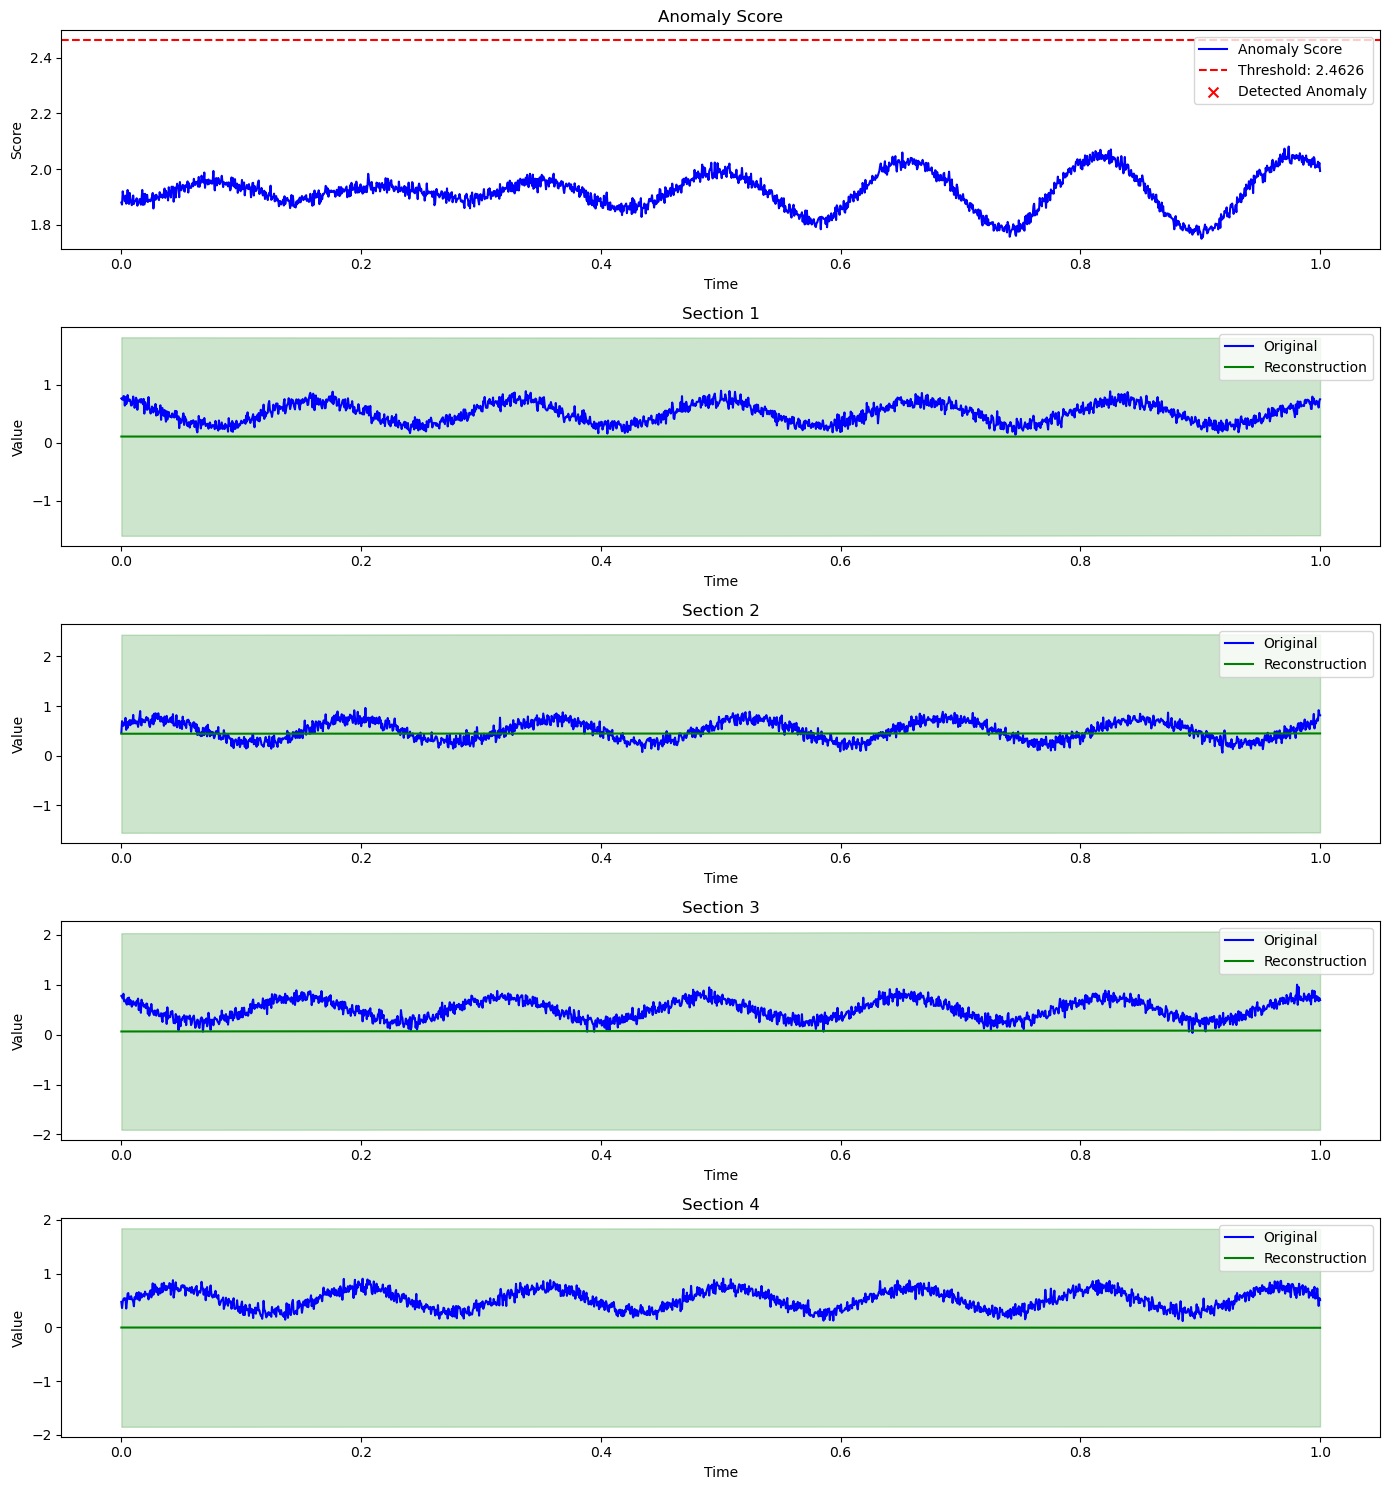

Sample 0 Performance:
Accuracy: 1.0000, F1: 1.0000
Precision: 1.0000, Recall: 1.0000

===== Section 2 Visualization =====
시각화 데이터 형태: torch.Size([950, 30])
시각화 라벨 형태: (950,)


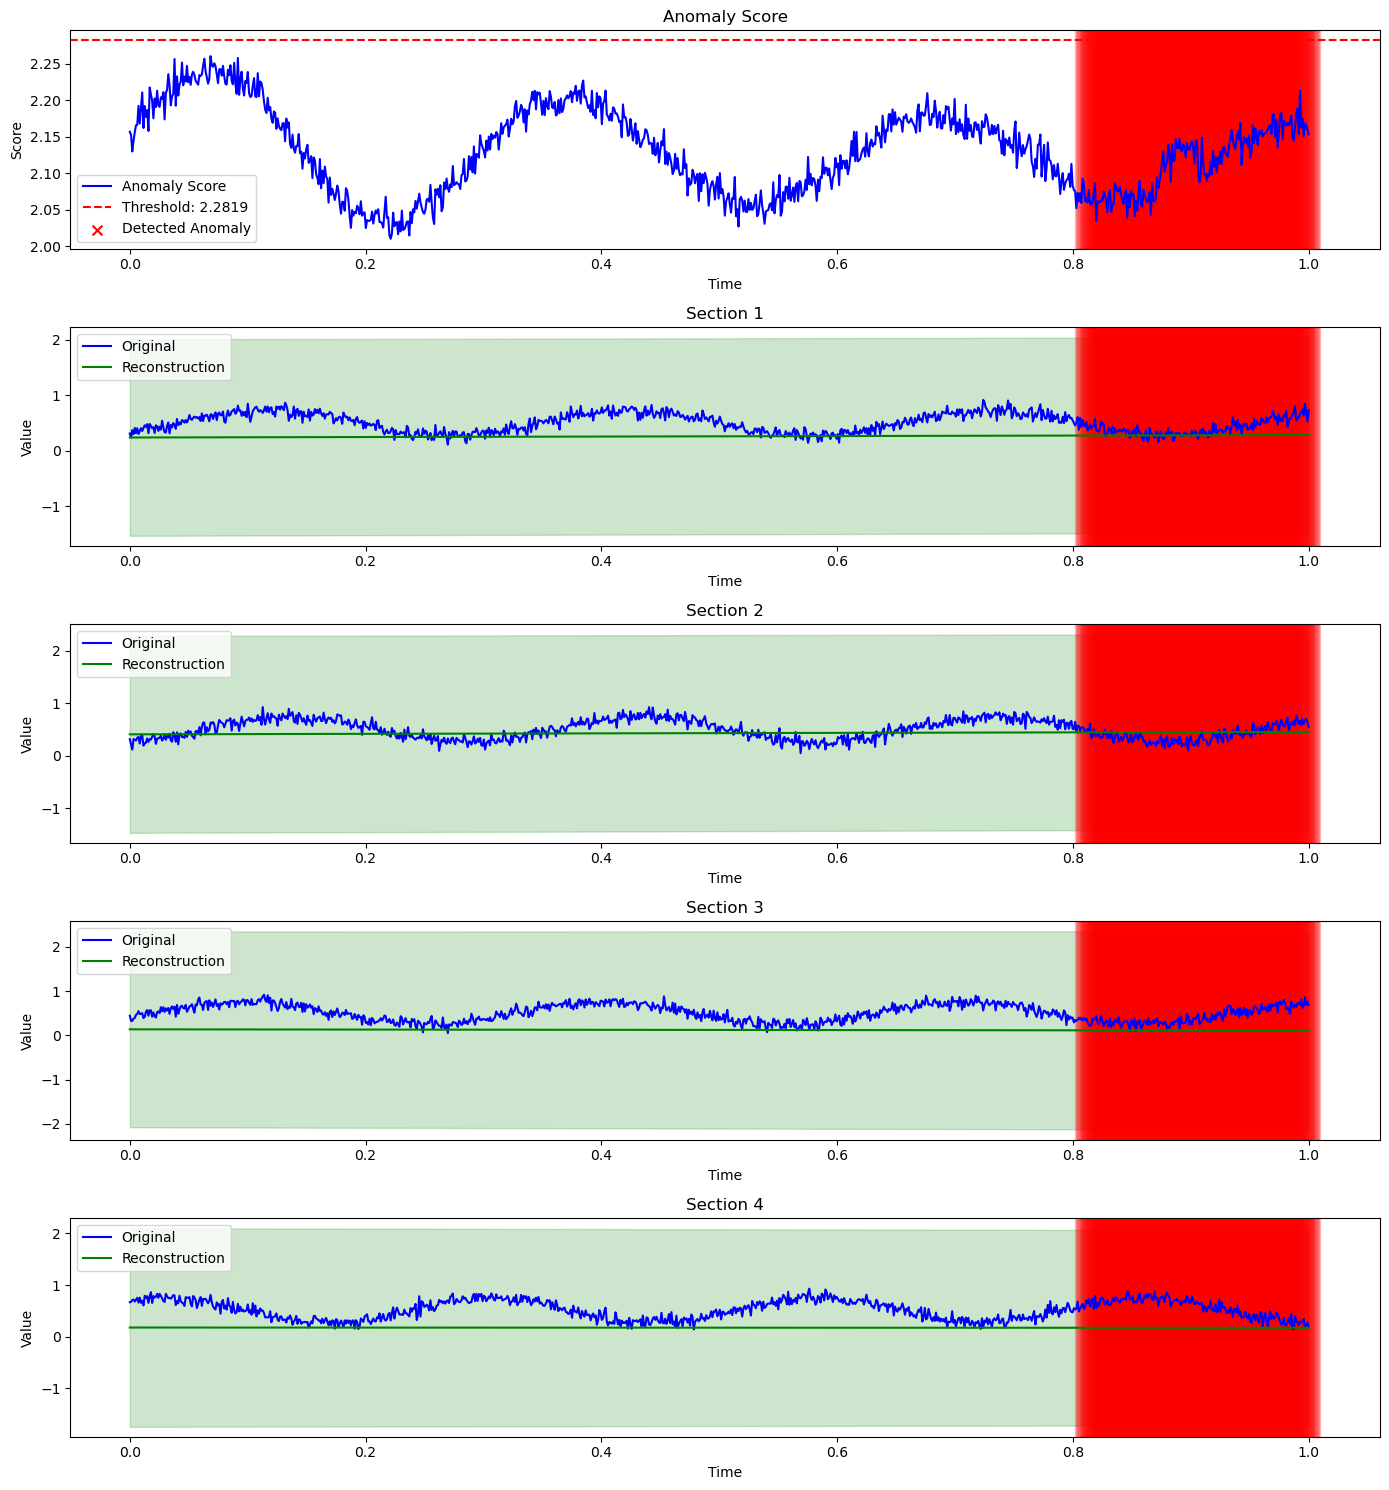

Sample 0 Performance:
Accuracy: 0.8105, F1: 0.4477
Precision: 0.4053, Recall: 0.5000

===== Section 3 Visualization =====
시각화 데이터 형태: torch.Size([3070, 30])
시각화 라벨 형태: (3070,)


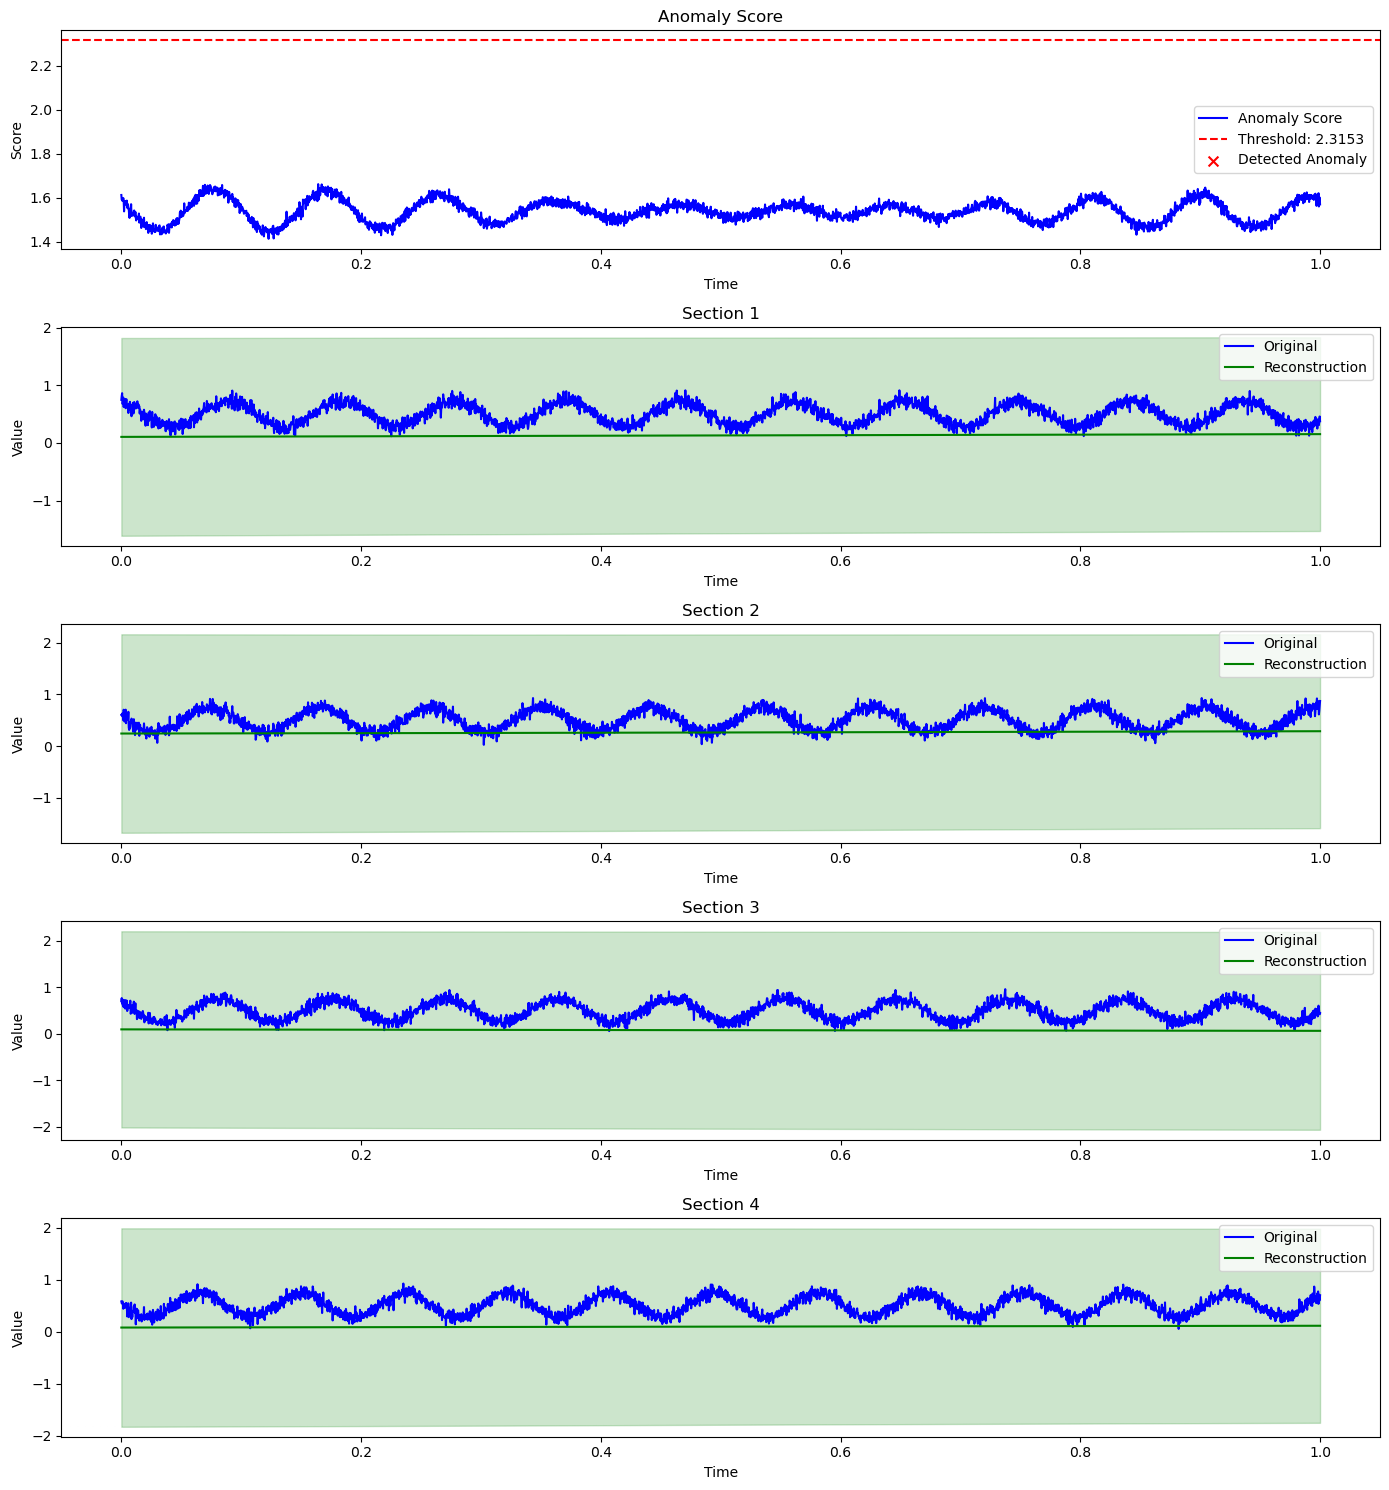

Sample 0 Performance:
Accuracy: 1.0000, F1: 1.0000
Precision: 1.0000, Recall: 1.0000

===== Section 4 Visualization =====
시각화 데이터 형태: torch.Size([650, 30])
시각화 라벨 형태: (650,)


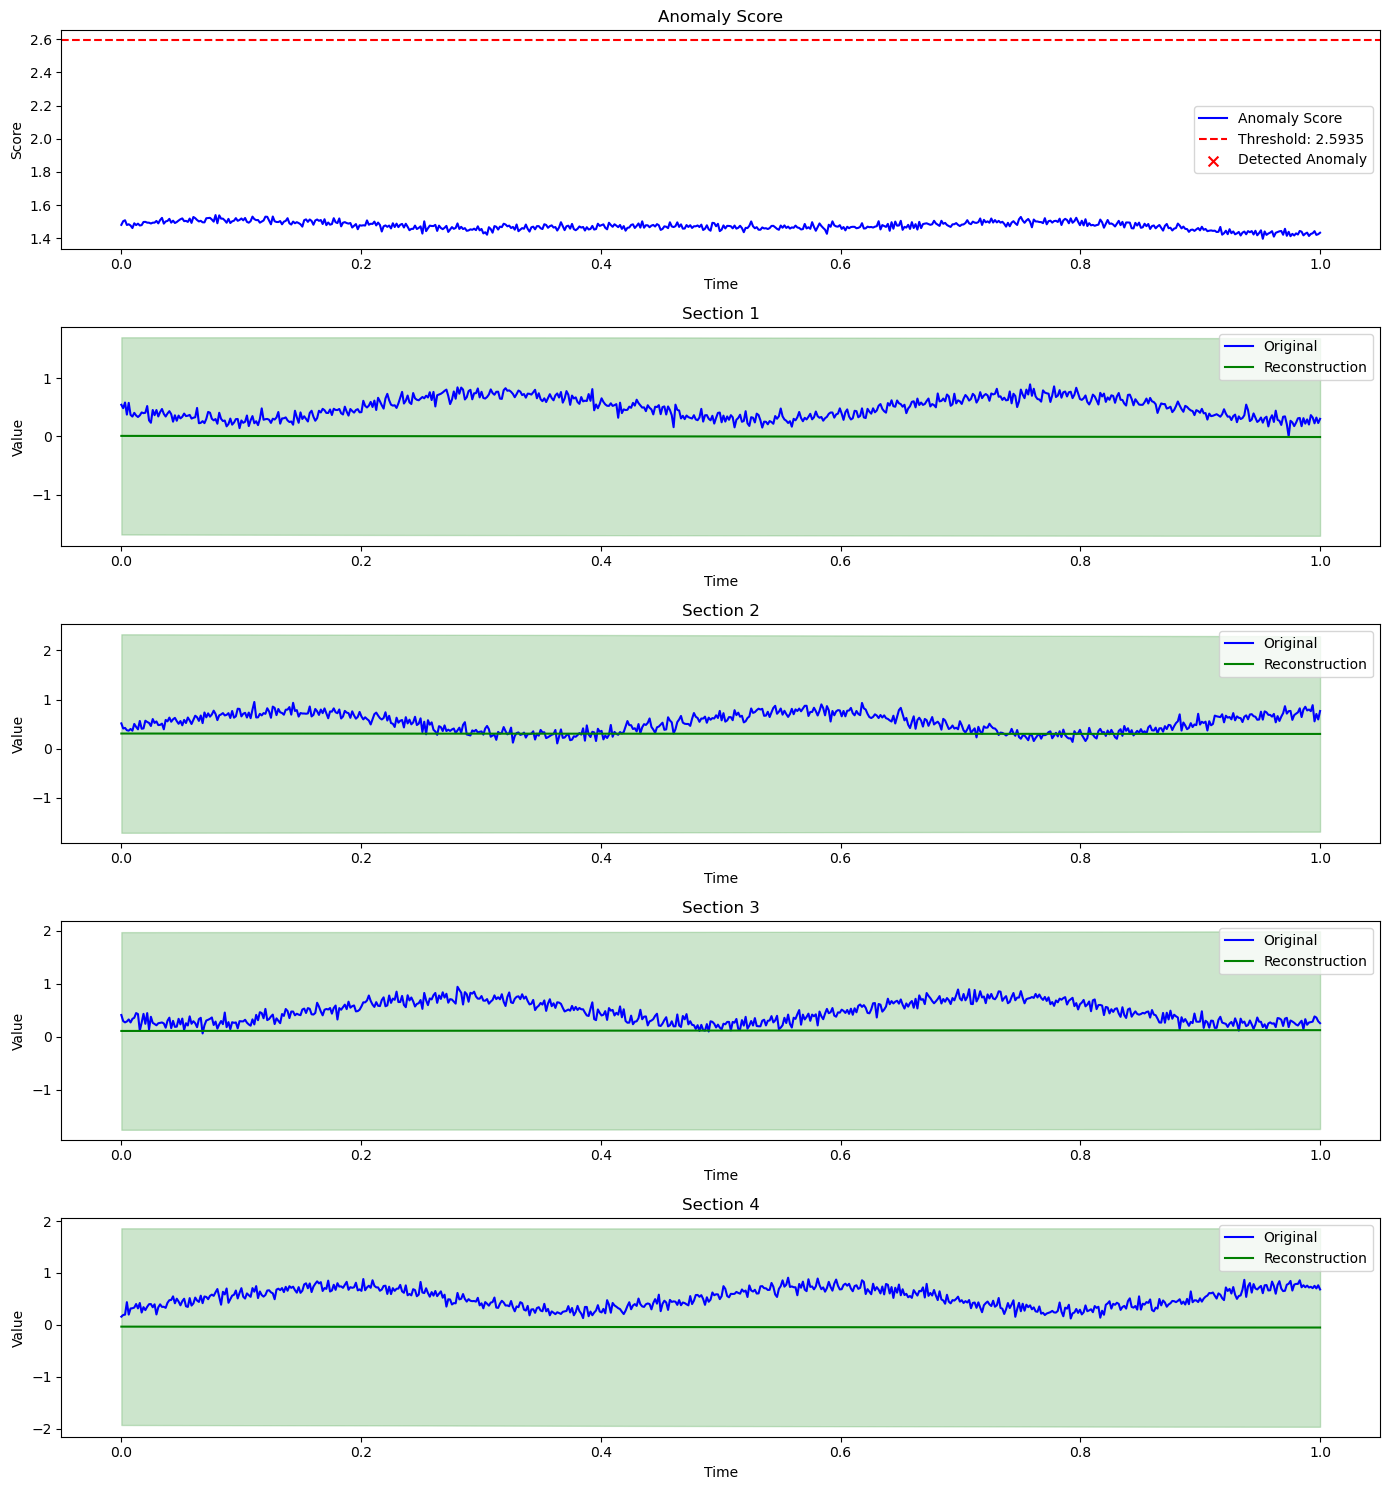

Sample 0 Performance:
Accuracy: 1.0000, F1: 1.0000
Precision: 1.0000, Recall: 1.0000

===== Section 5 Visualization =====
시각화 데이터 형태: torch.Size([1290, 30])
시각화 라벨 형태: (1290,)


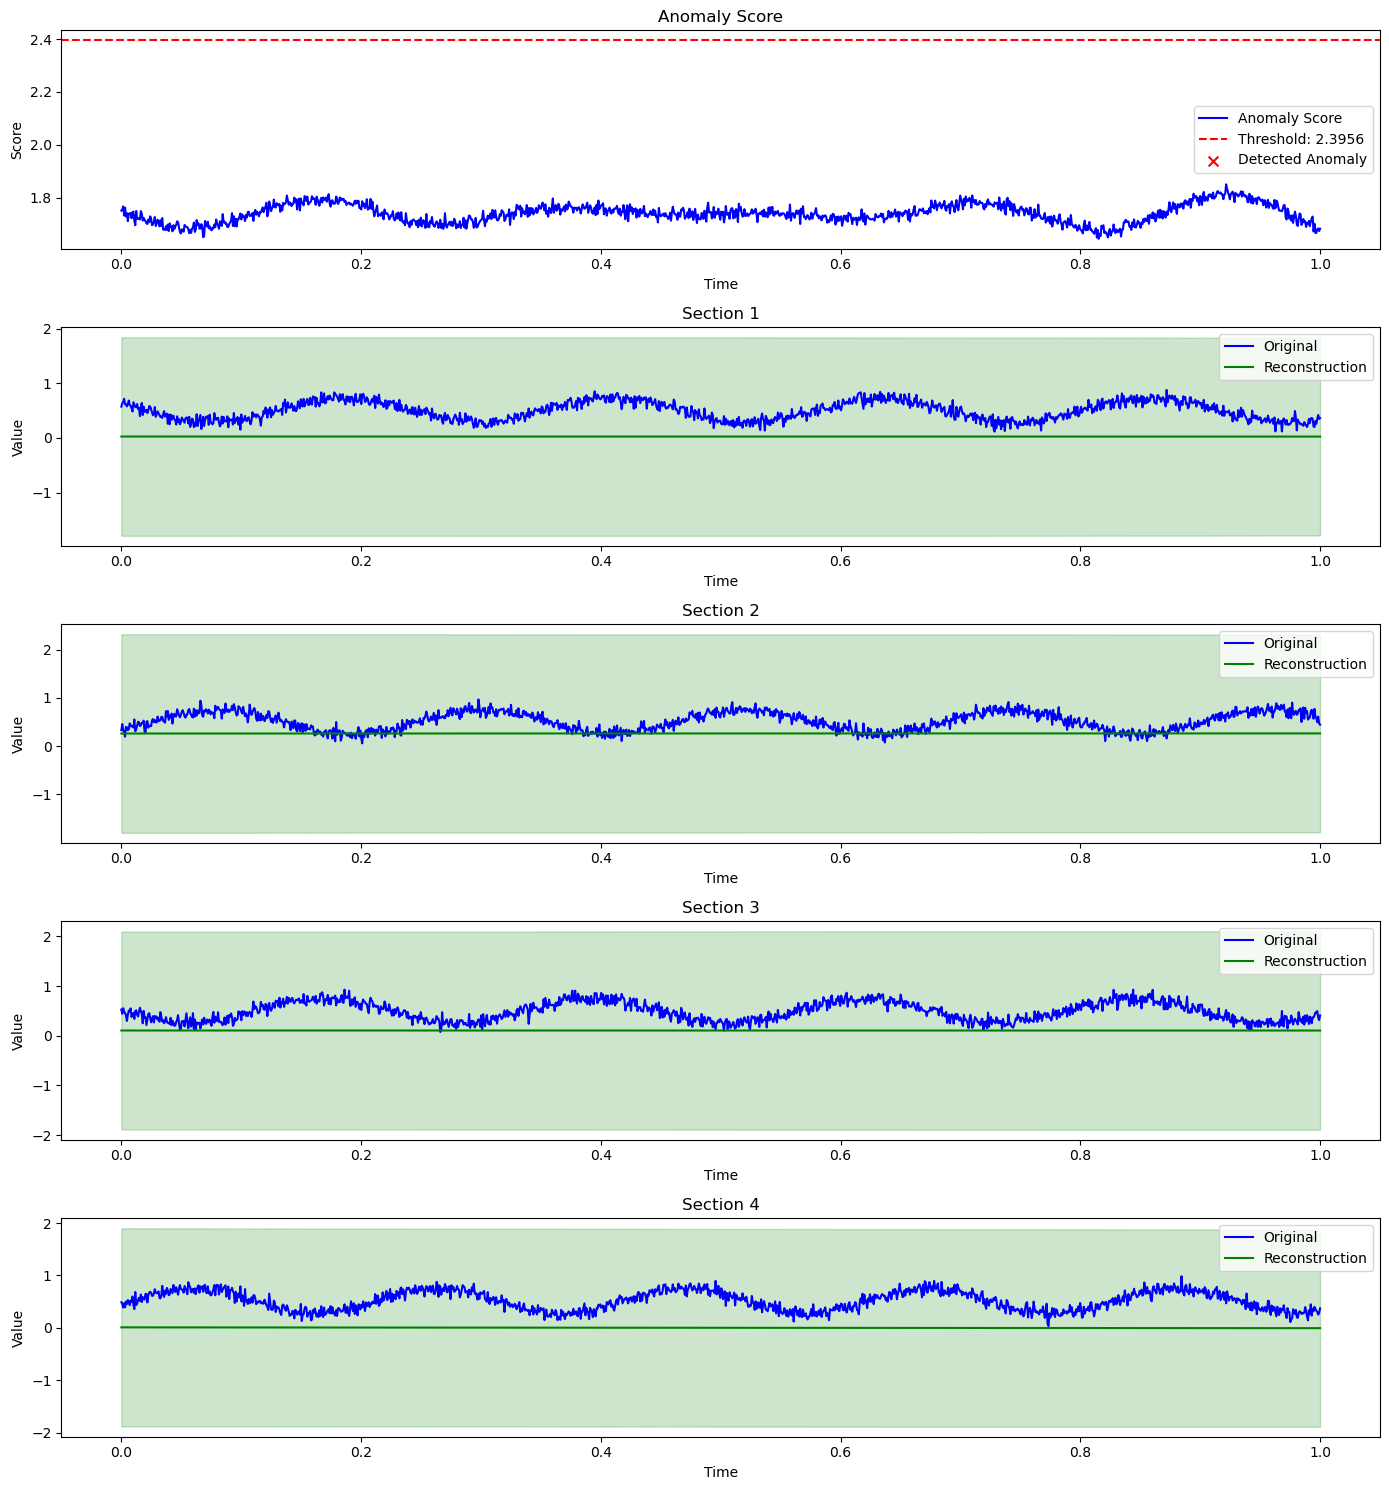

Sample 0 Performance:
Accuracy: 1.0000, F1: 1.0000
Precision: 1.0000, Recall: 1.0000


In [ ]:
def prepare_test_data(x_tst_all, lab_tst_all):
    """테스트 데이터와 라벨 준비 (형태 정보 출력)"""
    test_data_list = []
    test_labels_list = []
    
    for i, (x_tst, lab_tst) in enumerate(zip(x_tst_all, lab_tst_all)):
        # 텐서로 변환
        x_tst_tensor = torch.tensor(x_tst, dtype=torch.float32)
        print(f"섹션 {i+1} - 데이터 형태: {x_tst_tensor.shape}, 라벨 형태: {lab_tst.shape}")
        test_data_list.append(x_tst_tensor)
        test_labels_list.append(lab_tst)
    
    return test_data_list, test_labels_list

test_data_list, test_labels_list = prepare_test_data(x_tst_all, lab_tst_all)

all_metrics = []

for i, (test_data, test_labels) in enumerate(zip(test_data_list, test_labels_list)):
    print(f"\n===== 섹션 {i+1} 평가 =====")
    print(f"테스트 데이터 형태: {test_data.shape}")
    print(f"테스트 라벨 형태: {test_labels.shape}")
    
    # 검증 데이터 준비
    if len(test_data) > 100:
        val_size = min(100, len(test_data) // 5)
        
        # 여기서 데이터 형태 확인 및 조정이 필요
        if len(test_data.shape) == 3:  # (B, T, D) 형태
            val_data = test_data[:val_size]
            val_labels = test_labels[:val_size]
        else:  # (T, D) 형태
            val_data = test_data[:val_size]
            if len(test_labels.shape) == 1:  # (T,) 형태
                val_labels = test_labels[:val_size]
            else:
                val_labels = test_labels[:val_size, :]
        
        print(f"검증 데이터 크기: {val_data.shape}")
        print(f"검증 라벨 크기: {val_labels.shape if hasattr(val_labels, 'shape') else len(val_labels)}")
        
        # 임계값 찾기
        best_threshold, best_f1, _, _ = find_optimal_threshold(
            model, val_data, val_labels, device
        )
        print(f"최적 임계값: {best_threshold:.4f}, 검증 F1: {best_f1:.4f}")
    else:
        best_threshold = None
    
    # 섹션별 테스트 평가
    metrics = evaluate_irregular_model(
        model, test_data, test_labels, threshold=best_threshold, device=device
    )
    
    # 결과 출력
    print("\n성능 지표:")
    for key, value in metrics.items():
        if isinstance(value, float):
            print(f"{key}: {value:.4f}")
        else:
            print(f"{key}: {value}")
    
    # 결과 저장
    metrics['section'] = i+1
    all_metrics.append(metrics)
# 평균 성능 계산
print("\n===== All mean performance =====")
avg_metrics = {
    'accuracy': np.mean([m['accuracy'] for m in all_metrics]),
    'f1': np.mean([m['f1'] for m in all_metrics]),
    'precision': np.mean([m['precision'] for m in all_metrics]),
    'recall': np.mean([m['recall'] for m in all_metrics])
}

if all('auc' in m for m in all_metrics):
    avg_metrics['auc'] = np.mean([m['auc'] for m in all_metrics])

for key, value in avg_metrics.items():
    print(f"{key}: {value:.4f}")
    


def visualize_anomaly_detection(model, test_data, test_labels, threshold=None, sample_idx=0, max_features=4):
    """이상치 탐지 결과 시각화 (차원 처리 개선)"""    
    model.eval()
    
    # 데이터 준비
    if isinstance(test_data, np.ndarray):
        test_data = torch.tensor(test_data, dtype=torch.float32)
    
    # 차원 확인 및 출력
    print(f"시각화 데이터 형태: {test_data.shape}")
    print(f"시각화 라벨 형태: {test_labels.shape if hasattr(test_labels, 'shape') else len(test_labels)}")
    
    # 적절한 샘플 선택
    if len(test_data.shape) == 3:  # (B, T, D) 형태
        if sample_idx < test_data.shape[0]:
            x_sample = test_data[sample_idx:sample_idx+1].to(device)  
        else:
            print(f"샘플 인덱스 {sample_idx}가 범위를 벗어남. 첫 번째 샘플 사용.")
            x_sample = test_data[0:1].to(device)  
    else: 
        x_sample = test_data.unsqueeze(0).to(device)  
    
    # 시간 벡터 생성
    T = x_sample.shape[1]
    timestamps = torch.linspace(0, 1, T).unsqueeze(0).to(device)
    mask = torch.ones_like(timestamps).to(device)
    
    # 재구성 및 이상치 점수 계산
    with torch.no_grad():
        outputs = model(x_sample, timestamps, mask)
        recon_mu = outputs['recon_mu'].cpu().numpy()[0]
        recon_std = torch.exp(0.5 * outputs['recon_logvar']).cpu().numpy()[0]
        anomaly_scores = model.anomaly_score(x_sample, timestamps, mask)[0]
    
    # 원본 데이터
    x_np = x_sample.cpu().numpy()[0]
    
    # 라벨 처리
    if hasattr(test_labels, 'shape'):
        if len(test_labels.shape) == 2:  # (B, T) 형태
            y_true = test_labels[sample_idx] if sample_idx < len(test_labels) else test_labels[0]
        elif len(test_labels.shape) == 1 and len(test_data.shape) == 3:  # (B,) 형태, 데이터는 (B, T, D)
            # 시퀀스별 라벨 - 전체 시퀀스에 동일 라벨 적용
            y_true = test_labels[sample_idx] * np.ones(T) if sample_idx < len(test_labels) else test_labels[0] * np.ones(T)
        else:  # (T,) 형태, 데이터는 (T, D) 또는 (1, T, D)
            y_true = test_labels
    else:  # 리스트 등의 형태
        y_true = np.array(test_labels)
        if len(y_true.shape) == 1 and len(y_true) != T:
            y_true = np.zeros(T)  
    
    # 임계값 설정
    if threshold is None:
        normal_scores = anomaly_scores[y_true == 0]
        if len(normal_scores) > 0:
            threshold = np.mean(normal_scores) + 2 * np.std(normal_scores)
        else:
            threshold = np.percentile(anomaly_scores, 95)
    
    # 이상치 예측
    y_pred = (anomaly_scores > threshold).astype(int)
    
    # 시각화
    feature_count = min(max_features, x_np.shape[1])
    time_points = np.linspace(0, 1, T)
    
    fig, axes = plt.subplots(feature_count + 1, 1, figsize=(14, 3 * (feature_count + 1)))
    
    # 이상치 점수 시각화
    ax = axes[0]
    ax.plot(time_points, anomaly_scores, 'b-', label='Anomaly Score')
    ax.axhline(y=threshold, color='r', linestyle='--', label=f'Threshold: {threshold:.4f}')
    
    # 실제 이상치 영역 표시
    anomaly_regions = np.where(y_true == 1)[0]
    for idx in anomaly_regions:
        if idx < len(time_points):  
            ax.axvspan(time_points[idx] - 0.01, time_points[idx] + 0.01, alpha=0.2, color='red')
    
    # 탐지된 이상치 표시
    detected = np.where(y_pred == 1)[0]
    ax.scatter(time_points[detected], anomaly_scores[detected], color='red', marker='x', s=50, label='Detected Anomaly')
    
    ax.set_title('Anomaly Score')
    ax.set_xlabel('Time')
    ax.set_ylabel('Score')
    ax.legend()
    
    # 주요 특성별 시각화
    for i in range(feature_count):
        ax = axes[i + 1]
        
        # 원본 데이터
        ax.plot(time_points, x_np[:, i], 'b-', label='Original')
        
        # 재구성 데이터 (불확실성 포함)
        ax.plot(time_points, recon_mu[:, i], 'g-', label='Reconstruction')
        ax.fill_between(
            time_points,
            recon_mu[:, i] - 2 * recon_std[:, i],
            recon_mu[:, i] + 2 * recon_std[:, i],
            color='g', alpha=0.2
        )
        
        # 이상치 영역 표시
        for idx in anomaly_regions:
            if idx < len(time_points): 
                ax.axvspan(time_points[idx] - 0.01, time_points[idx] + 0.01, alpha=0.2, color='red')
        
        # 탐지된 이상치 표시
        for idx in detected:
            if idx < len(time_points) and idx < x_np.shape[0]: 
                ax.scatter(time_points[idx], x_np[idx, i], color='red', marker='x', s=50)
        
        ax.set_title(f'Section {i+1}')
        ax.set_xlabel('Time')
        ax.set_ylabel('Value')
        ax.legend()
    
    plt.tight_layout()
    plt.show()
    
    # 정확도 계산 (라벨과 예측이 동일한 형태인 경우만)
    if len(y_true) == len(y_pred):
        accuracy = accuracy_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred, average='macro')
        precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
        recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
        
        print(f"Sample {sample_idx} Performance:")
        print(f"Accuracy: {accuracy:.4f}, F1: {f1:.4f}")
        print(f"Precision: {precision:.4f}, Recall: {recall:.4f}")
    else:
        print(f"라벨 형태({len(y_true)})와 예측 형태({len(y_pred)})가 일치하지 않아 성능 계산 불가")
    
    return anomaly_scores, y_pred, y_true

# 샘플 시각화
for section_idx in range(len(test_data_list)):
    print(f"\n===== Section {section_idx+1} Visualization =====")
    sample_idx = 0  # 첫 번째 샘플
    
    # 섹션별 최적 임계값 사용
    threshold = all_metrics[section_idx]['threshold']
    
    # 시각화
    visualize_anomaly_detection(
        model,
        test_data_list[section_idx], 
        test_labels_list[section_idx],
        threshold=threshold,
        sample_idx=sample_idx
    )

In [ ]:
def train_anomaly_detector(data, dataset_name='dataset', num_epochs=20, batch_size=64, lr=1e-4, weight_decay=1e-4):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"사용 장치: {device}")
    
    # 데이터 형식 확인
    if 'x_trn' in data and 'x_tst' in data and 'lab_tst' in data:
        x_trn = data['x_trn']
        x_tst = data['x_tst']
        lab_tst = data['lab_tst']
        
        if isinstance(x_trn, list) and isinstance(x_tst, list) and isinstance(lab_tst, list):
            # 리스트 형식 - 다중 섹션으로 처리
            print(f"{dataset_name}: 리스트 형식 감지, {len(x_trn)}개 섹션으로 처리")
            all_results = []
            latent_dim = 64
            
            for i in range(len(x_trn)):
                print(f"\n섹션 {i+1}/{len(x_trn)} 처리 중")
                result = process_section(
                    x_trn[i], x_tst[i], lab_tst[i],
                    num_epochs=num_epochs,
                    batch_size=batch_size,
                    lr=lr,
                    weight_decay=weight_decay,
                    hidden_dim=128,
                    latent_dim=latent_dim, 
                    device=device
                )
                all_results.append(result)
            
            # 평균 성능 계산
            avg_precision = np.mean([r['metrics']['precision'] for r in all_results])
            avg_recall = np.mean([r['metrics']['recall'] for r in all_results])
            avg_f1 = np.mean([r['metrics']['f1'] for r in all_results])
            avg_auc = np.mean([r['metrics']['auc'] for r in all_results])
            
            print(f"\n{dataset_name} 평균 성능:")
            print(f"Precision: {avg_precision:.4f}")
            print(f"Recall: {avg_recall:.4f}")
            print(f"F1: {avg_f1:.4f}")
            print(f"AUC: {avg_auc:.4f}")
            
            return {
                'section_results': all_results,
                'avg_metrics': {
                    'precision': avg_precision,
                    'recall': avg_recall,
                    'f1': avg_f1,
                    'auc': avg_auc
                }
            }
        else:
            # 단일 데이터셋
            print(f"{dataset_name}: 단일 데이터셋 처리")
            result = process_section(
                x_trn, x_tst, lab_tst,
                num_epochs=num_epochs,
                batch_size=batch_size,
                lr=lr,
                weight_decay=weight_decay,
                hidden_dim=128,
                latent_dim=latent_dim, 
                device=device
            )
            
            print(f"\n{dataset_name} 성능:")
            print(f"Precision: {result['metrics']['precision']:.4f}")
            print(f"Recall: {result['metrics']['recall']:.4f}")
            print(f"F1: {result['metrics']['f1']:.4f}")
            print(f"AUC: {result['metrics']['auc']:.4f}")
            
            return result
    
    elif 'trn' in data and 'tst' in data and 'lab' in data:
        x_trn_all = data['trn']
        x_tst_all = data['tst']
        lab_tst_all = data['lab']
        
        print(f"{dataset_name}: 다중 섹션 형식 감지, {len(x_trn_all)}개 섹션")
        all_results = []
        
        for i in range(len(x_trn_all)):
            print(f"\n섹션 {i+1}/{len(x_trn_all)} 처리 중")
            result = process_section(
                x_trn_all[i], x_tst_all[i], lab_tst_all[i],
                num_epochs=num_epochs,
                batch_size=batch_size,
                lr=lr,
                weight_decay=weight_decay,
                hidden_dim=128,
                num_heads=4,
                device=device
            )
            all_results.append(result)
        
        # 평균 성능 계산
        avg_precision = np.mean([r['metrics']['precision'] for r in all_results])
        avg_recall = np.mean([r['metrics']['recall'] for r in all_results])
        avg_f1 = np.mean([r['metrics']['f1'] for r in all_results])
        avg_auc = np.mean([r['metrics']['auc'] for r in all_results])
        
        print(f"\n{dataset_name} 평균 성능:")
        print(f"Precision: {avg_precision:.4f}")
        print(f"Recall: {avg_recall:.4f}")
        print(f"F1: {avg_f1:.4f}")
        print(f"AUC: {avg_auc:.4f}")
        
        return {
            'section_results': all_results,
            'avg_metrics': {
                'precision': avg_precision,
                'recall': avg_recall,
                'f1': avg_f1,
                'auc': avg_auc
            }
        }
    
    else:
        raise ValueError("지원하지 않는 데이터 형식입니다.")


In [ ]:
from datasets.SMD.preprocess_SMD import SMD_Dataset
import pickle as pk

trimSyn_path = './data/MSCRED/trimSyn.pk'
with open(trimSyn_path, 'rb') as pkf:
    trimSyn_data = pk.load(pkf)

results = train_anomaly_detector(
    data=trimSyn_data,
    dataset_name='trimSyn',
    num_epochs=30,
    batch_size=1024
)

사용 장치: cpu
trimSyn: 리스트 형식 감지, 5개 섹션으로 처리

섹션 1/5 처리 중
x_tst_norm shape: (1720, 1, 30)
lab_tst shape: (1720,)
Anomaly ratio in this section: 0.0000
Epoch 1/30, Loss: 12.154969 (Recon NLL: 1.715484, Flow NLL: 104.394852, KL Div: 0.728782)
Epoch 2/30, Loss: 11.829212 (Recon NLL: 1.703308, Flow NLL: 101.258571, KL Div: 0.700448)
Epoch 3/30, Loss: 11.574740 (Recon NLL: 1.691470, Flow NLL: 98.831750, KL Div: 0.709560)
Epoch 4/30, Loss: 11.381010 (Recon NLL: 1.678988, Flow NLL: 97.018706, KL Div: 0.753310)
Epoch 5/30, Loss: 11.253352 (Recon NLL: 1.664664, Flow NLL: 95.884657, KL Div: 0.832599)
Epoch 6/30, Loss: 11.132590 (Recon NLL: 1.655017, Flow NLL: 94.772565, KL Div: 0.951947)
Epoch 7/30, Loss: 10.995477 (Recon NLL: 1.644590, Flow NLL: 93.504388, KL Div: 1.117727)
Epoch 8/30, Loss: 10.851777 (Recon NLL: 1.630518, Flow NLL: 92.206341, KL Div: 1.337281)
Epoch 9/30, Loss: 10.674942 (Recon NLL: 1.615174, Flow NLL: 90.589026, KL Div: 1.622910)
Epoch 10/30, Loss: 10.517875 (Recon NLL: 1.604170

In [125]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
import pickle as pk

# 간단한 오토인코더 모델
class SimpleAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super(SimpleAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim*2),
            nn.ReLU(),
            nn.Linear(hidden_dim*2, hidden_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim*2),
            nn.ReLU(),
            nn.Linear(hidden_dim*2, input_dim)
        )
    
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# 성능 평가 함수
def evaluate_model(y_true, y_score):
    # 이상치가 없는 경우 기본값 설정
    if np.sum(y_true) == 0:
        return {
            'precision': 0.0,
            'recall': 0.0,
            'f1': 0.0,
            'auc': 0.5,
            'threshold': 0.5
        }
    
    best_f1 = 0
    best_threshold = 0.5
    best_metrics = {}
    
    for threshold in np.linspace(0, 1, 100):
        y_pred = (y_score > threshold).astype(int)
        
        # 예측이 모두 0 또는 모두 1인 경우 스킵
        if np.sum(y_pred) == 0 or np.sum(y_pred) == len(y_pred):
            continue
            
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_metrics = {
                'precision': precision,
                'recall': recall,
                'f1': f1,
                'threshold': threshold
            }
    
    # 최적의 임계값을 찾지 못한 경우 (예: 모든 예측이 0 또는 1)
    if not best_metrics:
        best_metrics = {
            'precision': 0.0,
            'recall': 0.0,
            'f1': 0.0,
            'threshold': 0.5
        }
    
    # AUC 계산
    if len(np.unique(y_true)) > 1:  # 라벨이 두 개 이상일 때만 계산
        auc = roc_auc_score(y_true, y_score)
    else:
        auc = 0.5
    
    best_metrics['auc'] = auc
    return best_metrics

# 기본 모델 비교 함수
def compare_basic_models(x_trn_all, x_tst_all, lab_tst_all):
    results = {}
    
    for i in range(len(x_trn_all)):
        print(f"\n섹션 {i+1}/{len(x_trn_all)} 처리 중")
        x_train = x_trn_all[i]
        x_test = x_tst_all[i]
        y_test = lab_tst_all[i]
        
        # 데이터 정규화
        x_train_norm = (x_train - np.mean(x_train, axis=0)) / (np.std(x_train, axis=0) + 1e-10)
        x_test_norm = (x_test - np.mean(x_train, axis=0)) / (np.std(x_train, axis=0) + 1e-10)
        
        print(f"  훈련 데이터 형태: {x_train.shape}")
        print(f"  테스트 데이터 형태: {x_test.shape}")
        print(f"  테스트 라벨 형태: {y_test.shape}")
        
        anomaly_ratio = np.mean(y_test)
        print(f"  이상치 비율: {anomaly_ratio:.4f}")
        
        section_results = {}
        
        # 이상치가 아예 없는 경우 contamination 설정 주의
        contamination = max(0.01, anomaly_ratio) if anomaly_ratio > 0 else 0.01
        
        # 1. Isolation Forest
        print("  Isolation Forest 훈련 중...")
        iso_forest = IsolationForest(contamination=contamination, random_state=42)
        iso_forest.fit(x_train_norm)
        
        scores = -iso_forest.score_samples(x_test_norm)
        # 점수 정규화 (0~1 사이로)
        scores = (scores - np.min(scores)) / (np.max(scores) - np.min(scores) + 1e-10)
        section_results['isolation_forest'] = evaluate_model(y_test, scores)
        
        # 2. One-Class SVM
        print("  One-Class SVM 훈련 중...")
        try:
            nu = min(contamination, 0.5)  # nu는 0.5를 초과할 수 없음
            ocsvm = OneClassSVM(nu=nu, gamma='scale')
            ocsvm.fit(x_train_norm)
            
            scores = -ocsvm.score_samples(x_test_norm)
            scores = (scores - np.min(scores)) / (np.max(scores) - np.min(scores) + 1e-10)
            section_results['ocsvm'] = evaluate_model(y_test, scores)
        except Exception as e:
            print(f"  One-Class SVM 오류: {e}")
            section_results['ocsvm'] = {
                'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'auc': 0.5, 'threshold': 0.5
            }
        
        # 3. 오토인코더
        print("  오토인코더 훈련 중...")
        input_dim = x_train.shape[1]
        autoencoder = SimpleAutoencoder(input_dim)
        
        # 데이터 로더 설정
        train_dataset = TensorDataset(torch.tensor(x_train_norm, dtype=torch.float32))
        train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
        
        # 훈련 설정
        optimizer = torch.optim.Adam(autoencoder.parameters(), lr=1e-3)
        criterion = nn.MSELoss()
        
        # 훈련 루프
        epochs = 20
        for epoch in range(epochs):
            epoch_loss = 0
            for batch in train_loader:
                x_batch = batch[0]
                
                optimizer.zero_grad()
                outputs = autoencoder(x_batch)
                loss = criterion(outputs, x_batch)
                loss.backward()
                optimizer.step()
                
                epoch_loss += loss.item()
            
            if (epoch + 1) % 5 == 0:
                print(f"    Epoch {epoch+1}/{epochs}, Loss: {epoch_loss/len(train_loader):.6f}")
        
        # 이상 점수 계산
        autoencoder.eval()
        with torch.no_grad():
            x_test_tensor = torch.tensor(x_test_norm, dtype=torch.float32)
            reconstructed = autoencoder(x_test_tensor)
            reconstruction_error = torch.mean(torch.square(x_test_tensor - reconstructed), dim=1)
            scores = reconstruction_error.numpy()
            
            # 정규화
            scores = (scores - np.min(scores)) / (np.max(scores) - np.min(scores) + 1e-10)
        
        section_results['autoencoder'] = evaluate_model(y_test, scores)
        
        # 섹션 결과 저장
        results[f"section_{i}"] = section_results
        
        # 섹션 결과 출력
        print(f"\n섹션 {i+1} 결과:")
        for model_name, metrics in section_results.items():
            print(f"  {model_name}: F1={metrics['f1']:.4f}, AUC={metrics['auc']:.4f}")
    
    # 평균 성능 계산
    avg_results = {}
    for model_name in ['isolation_forest', 'ocsvm', 'autoencoder']:
        avg_precision = np.mean([results[f"section_{i}"][model_name]['precision'] for i in range(len(x_trn_all))])
        avg_recall = np.mean([results[f"section_{i}"][model_name]['recall'] for i in range(len(x_trn_all))])
        avg_f1 = np.mean([results[f"section_{i}"][model_name]['f1'] for i in range(len(x_trn_all))])
        avg_auc = np.mean([results[f"section_{i}"][model_name]['auc'] for i in range(len(x_trn_all))])
        
        avg_results[model_name] = {
            'precision': avg_precision,
            'recall': avg_recall,
            'f1': avg_f1,
            'auc': avg_auc
        }
    
    print("\n평균 성능:")
    for model_name, metrics in avg_results.items():
        print(f"{model_name}: Precision={metrics['precision']:.4f}, Recall={metrics['recall']:.4f}, F1={metrics['f1']:.4f}, AUC={metrics['auc']:.4f}")
    
    return results, avg_results

# 메인 실행 코드
if __name__ == "__main__":
    # 데이터 로드
    trimSyn_path = './data/MSCRED/trimSyn.pk'
    with open(trimSyn_path, 'rb') as pkf:
        data = pk.load(pkf)
    
    x_trn_all = data['x_trn']
    x_tst_all = data['x_tst']
    lab_tst_all = data['lab_tst']
    
    print(f"트레이닝 데이터 수: {len(x_trn_all)}")
    print(f"첫 번째 트레이닝 데이터 형태: {x_trn_all[0].shape}")
    print(f"테스트 데이터 수: {len(x_tst_all)}")
    for i, x_tst in enumerate(x_tst_all):
        print(f"테스트 섹션 {i} 형태: {x_tst.shape}, 라벨 형태: {lab_tst_all[i].shape}")
    
    # 모델 비교 실행
    results, avg_results = compare_basic_models(x_trn_all, x_tst_all, lab_tst_all)
    
    # 결과 비교 및 출력
    print("\n기존 AnomalyDetector 모델과 성능 비교:")
    print("AnomalyDetector: Precision=0.0397, Recall=0.1367, F1=0.0615, AUC=0.5074")
    
    for model_name, metrics in avg_results.items():
        if metrics['f1'] > 0:
            comparison = f"{model_name}: F1 {metrics['f1']:.4f} vs 0.0615 "
            if metrics['f1'] > 0.0615:
                comparison += f"(+{(metrics['f1']-0.0615)/0.0615*100:.1f}% 향상)"
            else:
                comparison += f"({(metrics['f1']-0.0615)/0.0615*100:.1f}% 감소)"
            print(comparison)

트레이닝 데이터 수: 5
첫 번째 트레이닝 데이터 형태: (10000, 30)
테스트 데이터 수: 5
테스트 섹션 0 형태: (1720, 30), 라벨 형태: (1720,)
테스트 섹션 1 형태: (950, 30), 라벨 형태: (950,)
테스트 섹션 2 형태: (3070, 30), 라벨 형태: (3070,)
테스트 섹션 3 형태: (650, 30), 라벨 형태: (650,)
테스트 섹션 4 형태: (1290, 30), 라벨 형태: (1290,)

섹션 1/5 처리 중
  훈련 데이터 형태: (10000, 30)
  테스트 데이터 형태: (1720, 30)
  테스트 라벨 형태: (1720,)
  이상치 비율: 0.0000
  Isolation Forest 훈련 중...
  One-Class SVM 훈련 중...
  오토인코더 훈련 중...
    Epoch 5/20, Loss: 0.017511
    Epoch 10/20, Loss: 0.005988
    Epoch 15/20, Loss: 0.003039
    Epoch 20/20, Loss: 0.001207

섹션 1 결과:
  isolation_forest: F1=0.0000, AUC=0.5000
  ocsvm: F1=0.0000, AUC=0.5000
  autoencoder: F1=0.0000, AUC=0.5000

섹션 2/5 처리 중
  훈련 데이터 형태: (10000, 30)
  테스트 데이터 형태: (950, 30)
  테스트 라벨 형태: (950,)
  이상치 비율: 0.1895
  Isolation Forest 훈련 중...
  One-Class SVM 훈련 중...


KeyboardInterrupt: 

In [25]:
### New data 
# MSL

from torch.utils.data import Dataset
from utils.mypath import MyPath
import ast
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class MSL(Dataset):
    base_folder = ''

    def __init__(self, fname, root=MyPath.db_root_dir('msl'), train=True, transform=None, sanomaly= None, mean_data=None, std_data=None):

        super(MSL, self).__init__()
        self.root = root
        self.transform = transform
        self.sanomaly = sanomaly
        self.train = train  # training set or test set
        self.classes = ['Normal', 'Anomaly']
        self.data = []
        self.targets = []
        wsz, stride = 200, 1

        with open(os.path.join(self.root, 'labeled_anomalies.csv'), 'r') as file:
            csv_reader = pandas.read_csv(file, delimiter=',')

        data_info = csv_reader[csv_reader['chan_id'] == fname]

        if self.train:
            self.base_folder += 'train'
        else:
            self.base_folder += 'test'
            labels = []
            for index, row in data_info.iterrows():
                anomalies = ast.literal_eval(row['anomaly_sequences'])
                length = row.iloc[-1]
                label = np.zeros([length], dtype=bool)
                for anomaly in anomalies:
                    label[anomaly[0]:anomaly[1] + 1] = True
                labels.extend(label)
            self.targets = np.asarray(labels)

            self.mean, self.std = mean_data, std_data

        file_path = os.path.join(self.root, self.base_folder, fname+'.npy')
        temp = np.load(file_path)
        if np.any(sum(np.isnan(temp))!=0):
            print('Data contains NaN which replaced with zero')
            temp = np.nan_to_num(temp)

        if self.train:
            self.mean = np.mean(temp, axis=0)
            self.std = np.std(temp , axis=0)
            # min_column = np.amin(temp, axis=0)
            # max_column = np.amax(temp, axis=0)
            # self.mean, self.std = min_column, max_column 
        else:
            self.mean, self.std = mean_data, std_data
            # range_val = (std_data - mean_data) + 1e-20
            # temp = (temp - mean_data) / range_val
            self.std[self.std == 0.0] = 1.0
            temp = (temp - self.mean) / self.std

        self.data = np.asarray(temp)
        self.data, self.targets = self.convert_to_windows(wsz, stride)

    def convert_to_windows(self, w_size, stride):
        windows = []
        wlabels = []
        sz = int((self.data.shape[0]-w_size)/stride)
        for i in range(0, sz):
            st = i * stride
            w = self.data[st:st+w_size]
            if sum(self.targets[st:st+w_size]) > 0:
                lbl = 1
            else: lbl=0
                    
            windows.append(w)
            wlabels.append(lbl)
        return np.stack(windows), np.stack(wlabels)

    def __getitem__(self, index):
        """
        Args:
            index (int): Index
        Returns:
            dict: {'ts': ts, 'target': index of target class, 'meta': dict}
        """
        # ts_org = self.data[index]
        ts_org = torch.from_numpy(self.data[index]).float().to(device)  # cuda

        if len(self.targets) > 0:
            # target = self.targets[index].astype(int)
            target = torch.tensor(self.targets[index].astype(int), dtype=torch.long).to(device)
            class_name = self.classes[target]
        else:
            target = 0
            class_name = ''

        ts_size = (ts_org.shape[0], ts_org.shape[1])

        out = {'ts_org': ts_org, 'target': target, 'meta': {'ts_size': ts_size, 'index': index, 'class_name': class_name}}

        return out

    def get_ts(self, index):
        ts = self.data[index]
        return ts

    def get_info(self):
        return self.mean, self.std

    def concat_ds(self, new_ds):
        self.data = np.concatenate((self.data, new_ds.data), axis=0)
        self.targets = np.concatenate((self.targets, new_ds.targets), axis=0)

    def __len__(self):
        return len(self.data)

    def extra_repr(self):
        return "Split: {}".format("Train" if self.train is True else "Test")

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
import torch
import torch.nn as nn
from torchdiffeq import odeint

class NeuralODE(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODE, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)

    def forward(self, t, y):
        return self.fc2(torch.relu(self.fc1(y)))

def extract_periodic_features(data):
    fft_result = np.fft.fft(data.to_numpy())
    periodic_features = np.abs(fft_result[:len(data)//2])  
    return torch.tensor(periodic_features, dtype=torch.float32)

def detect_spikes_with_periodicity(df, column_names, threshold):
    # 결측값 제거 및 데이터 준비
    data = df[column_names].dropna()
    data_tensor = torch.tensor(data.values, dtype=torch.float32)
    
    # 각 열에 대한 주기 특성 추출 및 결합
    periodic_features = []
    for col in column_names:
        periodic_feature = extract_periodic_features(data[col])
        periodic_feature = periodic_feature.unsqueeze(0).repeat(data_tensor.shape[0], 1)
        periodic_features.append(periodic_feature)
    
    periodic_features = torch.cat(periodic_features, dim=1)
    combined_input = torch.cat((data_tensor, periodic_features), dim=1)
    
    # Neural ODE 모델 초기화 및 학습
    model = NeuralODE(input_dim=combined_input.shape[1], hidden_dim=64)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    
    # ODE 솔버 실행
    t = torch.linspace(0, 1, data_tensor.size(0))
    y0 = combined_input[0].unsqueeze(0)
    solution = odeint(model, y0, t)
    
    # 스파이크 감지
    spikes = (solution[:, :, :len(column_names)] > threshold).float()
    spikes = spikes.mean(dim=(1, 2))
    
    # 원래 데이터프레임 길이에 맞추어 결과 조정
    spikes_full = np.zeros(len(df))
    valid_indices = data.index[data[column_names].notna().all(axis=1)]
    spikes_full[valid_indices] = spikes.detach().numpy()
    
    return spikes_full, data_tensor, valid_indices

def detect_anomalies(df, column_names, data_tensor, valid_indices):
    # One-Class SVM 실행
    oc_svm = OneClassSVM(kernel='rbf', gamma='auto').fit(data_tensor.numpy())
    oc_svm_predictions = oc_svm.predict(data_tensor.numpy())
    
    # 결과를 원본 데이터프레임 길이에 맞게 조정
    anomalies_full = np.zeros(len(df))
    anomalies_full[valid_indices] = (oc_svm_predictions == -1).astype(float)
    
    return anomalies_full

def visualize_results(df, column_name, spikes, anomalies):
    plt.figure(figsize=(15, 6))
    plt.plot(df['date'], df[column_name], label=column_name, marker='o', alpha=0.5)
    
    # Neural ODE 스파이크 시각화
    spike_mask = spikes > 0.5
    plt.scatter(df['date'][spike_mask], df[column_name][spike_mask], 
               color='red', label='Neural ODE Spikes', zorder=5)
    
    # One-Class SVM 이상치 시각화
    anomaly_mask = anomalies > 0.5
    plt.scatter(df['date'][anomaly_mask], df[column_name][anomaly_mask], 
               color='orange', label='One-Class SVM Anomalies', zorder=5)
    
    plt.title('Spike Detection and Anomaly Detection')
    plt.xlabel('Date')
    plt.ylabel('Values')
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

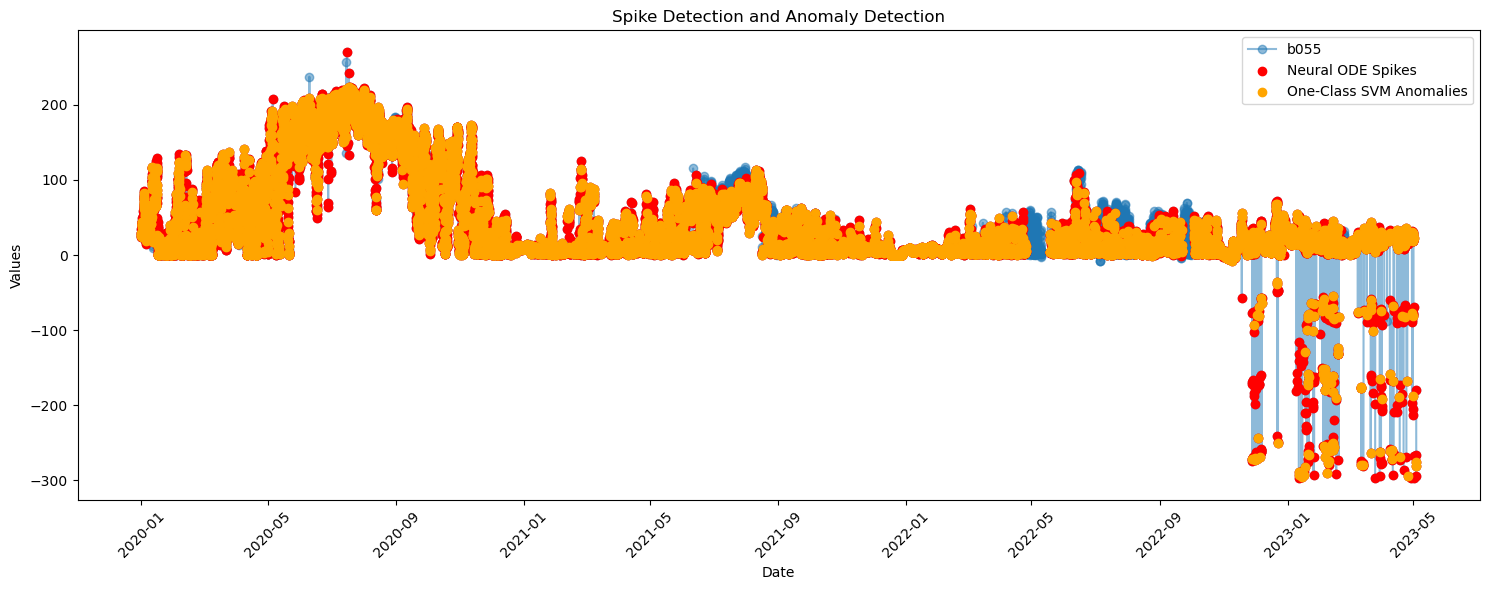

In [66]:
# 데이터 준비
columns = ['b055', 'b103', 'b166', 'b002', 'b084']
threshold = 2

# 스파이크 감지 실행
spikes, data_tensor, valid_indices = detect_spikes_with_periodicity(df, columns, threshold)

# 이상치 감지 실행
anomalies = detect_anomalies(df, columns, data_tensor, valid_indices)

# 결과 시각화
visualize_results(df, 'b055', spikes, anomalies)

In [46]:
import torch
import torch.nn as nn
import torchdiffeq  # Neural ODE library
import matplotlib.pyplot as plt

class ODEFunc(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(ODEFunc, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)
    
    def forward(self, t, y):
        y = torch.relu(self.fc1(y))
        return self.fc2(y)

class NeuralODEModel(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODEModel, self).__init__()
        self.odefunc = ODEFunc(input_dim, hidden_dim)
    
    def forward(self, y0, t):
        return torchdiffeq.odeint(self.odefunc, y0, t)


# Training loop for Neural ODE
def train_ode_model(model, data, time, epochs=500, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        optimizer.zero_grad()

        # Initial condition (y0) is the first observation
        y0 = data[0].unsqueeze(0)  # Ensure y0 is of shape [1, num_features]

        # Forward pass through the ODE model
        pred = model(y0, time)

        # Compute loss (reconstruction error)
        huber_loss = nn.HuberLoss()
        loss = huber_loss(pred, data.unsqueeze(0))  # Ensure data has proper shape [1, num_features, num_timesteps]

        # Backpropagation
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f'Epoch {epoch}, Loss: {loss.item()}')

# Anomaly detection: Calculate reconstruction error as anomaly score
def detect_anomalies(model, data, time, threshold=0.1):
    y0 = data[0]
    pred = model(y0, time)
    reconstruction_error = torch.mean((pred - data) ** 2, dim=1)
    anomalies = reconstruction_error > threshold
    return anomalies, reconstruction_error

def plot_predictions(time, true_data, predicted_data):
    num_vars = true_data.shape[1]
    
    plt.figure(figsize=(12, 6 * num_vars))
    for i in range(num_vars):
        plt.subplot(num_vars, 1, i+1)
        plt.plot(time.numpy(), true_data[:, i].numpy(), label='True Data')
        plt.plot(time.numpy(), predicted_data[:, i].detach().numpy(), label='Predicted Data', linestyle='--')
        plt.xlabel('Time (hours)')
        plt.ylabel(f'Variable {i+1}')
        plt.legend()
    plt.tight_layout()
    plt.show()

In [21]:
from fancyimpute import IterativeImputer

# Initialize and train the model
csv_file_path = './CSV data/GT/GT_final_date.csv'  
df = pd.read_csv(csv_file_path)

# Convert 'date' to numerical format (e.g., hours since start)
df['date'] = pd.to_datetime(df['date'])
df['date_numeric'] = (df['date'] - df['date'].min()).dt.total_seconds() / 3600

# Include 'date_numeric' in the imputation process
df2 = df.drop(['date'], axis=1)
data = df2.values

# Initialize MICE imputer
mice_imputer = IterativeImputer()

# Perform imputation
imputed_data = mice_imputer.fit_transform(data)

# Convert imputed data back to DataFrame
imputed_df = pd.DataFrame(imputed_data, columns=df2.columns)
imputed_df['date'] = df['date'] 
imputed_df['date_numeric'] = (imputed_df['date'] - imputed_df['date'].min()).dt.total_seconds() / 3600

In [23]:
# Ensure time steps are unique and sufficiently spaced
time = torch.tensor(imputed_df['date_numeric'].values, dtype=torch.float32)
time_diff = time.diff()

# Adjust time steps if any are zero or too small
min_time_step = 1e-2  # Set a minimum allowed time step
time_diff = torch.where(time_diff == 0, min_time_step, time_diff)  # Replace zero differences

# Recalculate time from the adjusted differences
time_adjusted = torch.cumsum(time_diff, dim=0)
time_adjusted = torch.cat((torch.tensor([time[0]]), time_adjusted))  # Include the initial time

# Normalize time between 0 and 1
time_normalized = (time_adjusted - time_adjusted.min()) / (time_adjusted.max() - time_adjusted.min())

# Convert imputed data to PyTorch tensor
data = torch.tensor(imputed_df.drop(['date', 'date_numeric'], axis=1).values, dtype=torch.float32)

In [24]:
# Initialize and train the model
input_dim = data.shape[1]  # Number of features in the data
hidden_dim = 50  # Hidden dimension size

ode_model = NeuralODEModel(input_dim, hidden_dim)
train_ode_model(ode_model, data, time_normalized)

# Predict and plot
y0 = data[0].unsqueeze(0)  # Initial condition for prediction
predicted = ode_model(y0, time_normalized)

/opt/anaconda3/envs/career/lib/python3.11/site-packages/torch/nn/modules/loss.py:999: UserWarning: Using a target size (torch.Size([1, 29256, 6])) that is different to the input size (torch.Size([29256, 1, 6])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.huber_loss(input, target, reduction=self.reduction, delta=self.delta)


Epoch 0, Loss: 6429071.0
Epoch 10, Loss: 6169923.5
Epoch 20, Loss: 6042227.5
Epoch 30, Loss: 5962905.0
Epoch 40, Loss: 5904445.5
Epoch 50, Loss: 5860411.5
Epoch 60, Loss: 5819851.0
Epoch 70, Loss: 5778532.0
Epoch 80, Loss: 5736408.0
Epoch 90, Loss: 5696644.0
Epoch 100, Loss: 5656487.0
Epoch 110, Loss: 5617336.5
Epoch 120, Loss: 5577563.0
Epoch 130, Loss: 5539727.5
Epoch 140, Loss: 5502061.5
Epoch 150, Loss: 5462732.0
Epoch 160, Loss: 5426233.0
Epoch 170, Loss: 5389188.0
Epoch 180, Loss: 5354967.5
Epoch 190, Loss: 5317069.5
Epoch 200, Loss: 5283030.5
Epoch 210, Loss: 5247810.5
Epoch 220, Loss: 5215267.0
Epoch 230, Loss: 5182472.0
Epoch 240, Loss: 5152455.0
Epoch 250, Loss: 5120677.0
Epoch 260, Loss: 5091159.0
Epoch 270, Loss: 5063383.5
Epoch 280, Loss: 5035992.5
Epoch 290, Loss: 5009796.5
Epoch 300, Loss: 4984998.0
Epoch 310, Loss: 4959976.5
Epoch 320, Loss: 4936718.0
Epoch 330, Loss: 4913600.5
Epoch 340, Loss: 4891809.0
Epoch 350, Loss: 4870829.5
Epoch 360, Loss: 4850446.0
Epoch 370, L

In [27]:
import torch
import torchdiffeq
from nflows import transforms, distributions, flows

class FlowLayer(torch.nn.Module):
    def __init__(self, input_dim):
        super(FlowLayer, self).__init__()
        self.base_dist = distributions.StandardNormal([input_dim])
        self.transform = transforms.CompositeTransform([
            transforms.AffineCoupling(input_dim=input_dim // 2),
            transforms.ActNorm(input_dim),
        ])
        self.flow = flows.Flow(self.transform, self.base_dist)

    def forward(self, x):
        # Forward pass through normalizing flow
        z, log_det = self.flow._transform.forward(x)
        return z, log_det

class NeuralODEModel(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODEModel, self).__init__()
        self.odefunc = torch.nn.Sequential(
            torch.nn.Linear(input_dim, hidden_dim),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, y0, t):
        return torchdiffeq.odeint(self.odefunc, y0, t)

class CombinedModel(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(CombinedModel, self).__init__()
        self.flow_layer = FlowLayer(input_dim)
        self.ode_layer = NeuralODEModel(input_dim, hidden_dim)

    def forward(self, x, t):
        # Forward pass through normalizing flow first
        z, log_det = self.flow_layer(x)
        # Then pass through the neural ODE
        z_ode = self.ode_layer(z, t)
        return z_ode, log_det

# Loss function that combines reconstruction and flow log-likelihood
def loss_function(pred, true, log_det, weight=1.0):
    # Reconstruction loss (e.g., MSE)
    reconstruction_loss = torch.nn.functional.mse_loss(pred, true)
    # Flow log-likelihood loss
    flow_loss = -log_det.mean()
    return reconstruction_loss + weight * flow_loss

# Example training loop
def train_combined_model(model, data, time, epochs=100, lr=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        # Initial condition for ODE
        y0 = data[0].unsqueeze(0)
        pred, log_det = model(y0, time)

        # Compute loss
        loss = loss_function(pred, data, log_det)

        # Backpropagation
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f'Epoch {epoch}, Loss: {loss.item()}')

### ID-CNN & LSTM-AE

In [21]:
reconstructed_data.index = reconstructed_data['ds']
reconstructed_data = reconstructed_data.drop(['ds'], axis = 1)

In [23]:
prof1.index = prof1['ds']
prof1 = prof1.drop(['Date/Time', 'ds'], axis = 1)

In [25]:
# Input
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 
num_samples = len(signal_train) 

# 추세와 계절성 데이터 추출 (이전에 설명한 방법 사용)
input_layer = Input(shape=(num_samples, 1))
conv1 = Conv1D(filters=16, kernel_size=5, activation='relu')(input_layer)
maxpool1 = MaxPooling1D(pool_size=2)(conv1)
conv2 = Conv1D(filters=32, kernel_size=5, activation='relu')(maxpool1)
maxpool2 = MaxPooling1D(pool_size=2)(conv2)
flatten = Flatten()(maxpool2)

# 추세 및 계절성 패턴을 추출하는 모델 생성
model = keras.Model(inputs = input_layer, outputs = flatten)
model.compile(optimizer = 'adam', loss = 'mse')

train_data = signal_train.reshape(1, len(signal_train), 1)
model.fit(train_data, train_data, epochs=50, batch_size=16, validation_data=(train_data, train_data))
val_data = signal_valid.reshape(1, num_samples - len(signal_valid), 1)
predictions = model.predict(val_data)

# LSTM Autoencoder 모델 정의
encoding_dim = 64
timesteps = num_samples
features = 1

Epoch 1/50


ValueError: in user code:

    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1377, in train_function  *
        return step_function(self, iterator)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1360, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1349, in run_step  **
        outputs = model.train_step(data)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1127, in train_step
        loss = self.compute_loss(x, y, y_pred, sample_weight)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1185, in compute_loss
        return self.compiled_loss(
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/si

In [26]:
num_series = 1
epochs = 10
window_size = 10

# 1D CNN (extract trend & seasonality)
def extract_trend_seasonality(series, window_size):
    model = Sequential([
        Conv1D(filters = 32, kernel_size = window_size, activation = 'relu', input_shape = (None, 1)),
        MaxPooling1D(pool_size = 2),
        LSTM(50, activation = 'relu'),
        Dense(1)
    ])

    model.compile(optimizer = 'adam', loss = 'mse')
    series = np.array(series).reshape((num_series, -1, 1))
    model.fit(series, series, epochs = epochs)

    # 추출된 트렌드 및 시즌얼리 데이터
    trend_seasonality = model.predict(series)
    return trend_seasonality

# LSTM을 통한 훈련
def train_lstm_on_trend_seasonality(trend_seasonality):
    model = Sequential([
        LSTM(50, activation='relu', input_shape = (None, 1), return_sequences = True),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mae')
    trend_seasonality = np.array(trend_seasonality).reshape((num_series, -1, 1))
    model.fit(trend_seasonality, trend_seasonality, epochs = epochs)

    return model

# 트렌드 및 시즌얼리 데이터 추출
trend_seasonality = extract_trend_seasonality(signal_train, window_size)

# LSTM을 통한 훈련
lstm_model = train_lstm_on_trend_seasonality(trend_seasonality)


Epoch 1/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 2/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 3/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 4/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 5/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 6/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 7/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 8/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 9/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 10/10
1/1 [==============================] - 0s 436ms/step
Epoch 1/10
1/1 [==============================] - 1s 607ms/step - loss: 0.0015
Epoch 2/10
1/1 [==============================] - 0s 3ms/step - loss: 6.6912e-06
Epoch 3/10
1/1 [==============================] - 0s 3ms/step - loss: 0.0014
Epoch 4/10
1/1

In [88]:
# 예측 및 시각화
signal_test[np.isnan(signal_test)] = 0
test_series = signal_test
test_series = np.array(test_series).reshape((-1, 1))

predicted_trend_seasonality = lstm_model.predict(test_series.reshape((1, -1, 1)))

1/1 [==============================] - 1s 662ms/step


In [84]:
predicted_trend_seasonality

array([[0.00475079]], dtype=float32)

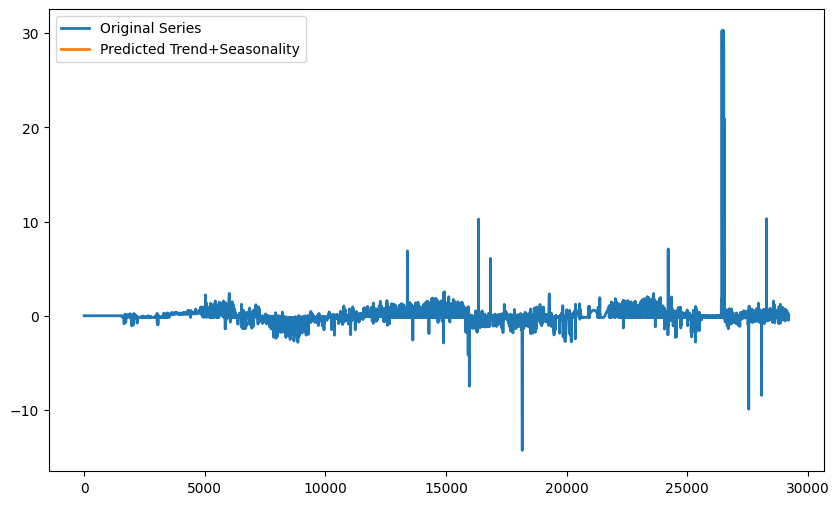

In [83]:
plt.figure(figsize=(10, 6))
plt.plot(test_series[:, :], label='Original Series', linewidth=2)
plt.plot(predicted_trend_seasonality[:, :], label='Predicted Trend+Seasonality', linewidth=2)
plt.legend()
plt.show()

In [61]:
predicted_trend_seasonality = lstm_model.predict(test_series)

1/1 [==============================] - 1s 699ms/step


### LSTM-AE with reconstructed_data as normal

In [58]:
reconstructed_data.index = pd.to_datetime(reconstructed_data['ds'])
reconstructed_data = reconstructed_data.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/1548268338.py:2: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [59]:
# orignal data
prof1.index = pd.to_datetime(prof1['ds'])
prof1 = prof1.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/2715252278.py:3: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [60]:
### split data
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 

# set window length
window_length = 12 * 2

train_windows = []

for window_start in range(0, len(signal_train) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_train[window_range])
    train_windows.append(window)
    
# shape of training set
x_train = np.array(train_windows)
x_train.shape

valid_windows = []
for window_start in range(0, len(signal_valid) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_valid[window_range])
    valid_windows.append(window)
    
# shape of validation set
x_valid = np.array(valid_windows)
x_valid.shape

test_windows = []

for window_start in range(0, len(signal_test) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_test[window_range])
    test_windows.append(window)

In [79]:
### LSTM Auto-Encoder Model
# optimizer list: adam, adamW, adadelta, adagrad, adamax, nadam

input_length = window_length
input_dim = 1 # number of variable
hidden_dim = 5
batch_size = 64
epochs = 100
opt = keras.optimizers.Adam(learning_rate=0.0005)

def model():
    m = Sequential()
    m.add(LSTM(units=4 * hidden_dim, activation='relu', input_shape=(input_length, input_dim), return_sequences=True))
    m.add(Dropout(rate=0.3))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=4 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(Dense(1))
    return m

# https://gooopy.tistory.com/90
m = model()
m.compile(loss='mse', optimizer=opt) # adam to rmsprop
m.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_6 (LSTM)               (None, 24, 20)            1760      
                                                                 
 dropout_6 (Dropout)         (None, 24, 20)            0         
                                                                 
 lstm_7 (LSTM)               (None, 24, 10)            1240      
                                                                 
 dropout_7 (Dropout)         (None, 24, 10)            0         
                                                                 
 lstm_8 (LSTM)               (None, 24, 5)             320       
                                                                 
 dropout_8 (Dropout)         (None, 24, 5)             0         
                                                                 
 lstm_9 (LSTM)               (None, 24, 5)            

In [80]:
checkpointer = ModelCheckpoint(filepath = "lstm.autoencoder.weights.best.hdf5", verbose = 1, save_best_only = True)
earlystopper = EarlyStopping(monitor = 'val_loss', patience = 10, verbose = 0)
tbCallBack = TensorBoard(log_dir = './lstm.autoencoder.tb.graph', histogram_freq = 0, write_graph = True, write_images = True)

In [81]:
history = m.fit(x_train, x_train, batch_size = batch_size, epochs = epochs, validation_data = (x_valid, x_valid), 
                callbacks = [checkpointer, earlystopper, tbCallBack], verbose = 0).history


Epoch 1: val_loss improved from inf to 0.00350, saving model to lstm.autoencoder.weights.best.hdf5

Epoch 2: val_loss did not improve from 0.00350

Epoch 3: val_loss did not improve from 0.00350

Epoch 4: val_loss did not improve from 0.00350

Epoch 5: val_loss did not improve from 0.00350

Epoch 6: val_loss did not improve from 0.00350

Epoch 7: val_loss did not improve from 0.00350

Epoch 8: val_loss did not improve from 0.00350

Epoch 9: val_loss did not improve from 0.00350

Epoch 10: val_loss did not improve from 0.00350

Epoch 11: val_loss did not improve from 0.00350


In [82]:
pred_x_valid = m.predict(x_valid)

67/67 [==============================] - 1s 5ms/step


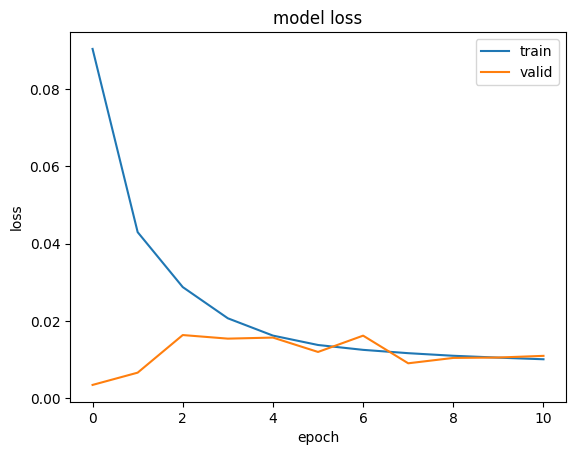

In [83]:
# summarize history for loss
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='best')
plt.show()

In [84]:
x_test = np.array(test_windows)
pred_x_test = m.predict(x_test)

913/913 [==============================] - 5s 5ms/step


In [85]:
# calculate error score
all_errors_valid = pd.Series(np.squeeze((x_valid.shape[:-1]) - pred_x_valid.reshape(pred_x_valid.shape[:-1])[:,:]).flatten())
all_errors_test = pd.Series(np.squeeze((x_test.shape[:-1]) - pred_x_test.reshape(pred_x_test.shape[:-1])[:,:]).flatten())

In [86]:
# calculate error score (window)
def sum_abs_errors_window(errors_in_window):
    return np.sum(np.abs(errors_in_window))

errors_test_per_window = np.squeeze(x_test.shape[:-1] -  pred_x_test.reshape(pred_x_test.shape[:-1])[:,:])
sum_abs_errors_window_0 = np.sum(np.abs(errors_test_per_window[0]))
sum_abs_errors_per_window = pd.Series([sum_abs_errors_window(errors_in_window) for errors_in_window in errors_test_per_window])

In [93]:
# Top anomalous windows ranked and get index
pred_outlier_indices = sum_abs_errors_per_window.nlargest(10).index.values

In [94]:
intervel_length = 1

In [95]:
def highlightComaprison(series, index, colorSTR):
    # Create a mask to identify where the Series values equal 4
    for i in range(len(index)):
        val = series[index[i]]
        mask = ((series) == val) 
        
        # Find the start and end indices of each continuous section where the value equals 4
        section_start = mask & ~mask.shift(fill_value=False)
        section_end = mask & ~mask.shift(-1, fill_value=False)
        
        for start, end in zip(section_start[section_start].index, section_end[section_end].index):
            plt.axvspan(start, end, color=colorSTR, alpha = 0.8)

In [96]:
test = pd.Series(signal_test)
test.index = prof1['2020-01-01':'2023-05-01'].index

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/4180722373.py:4: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



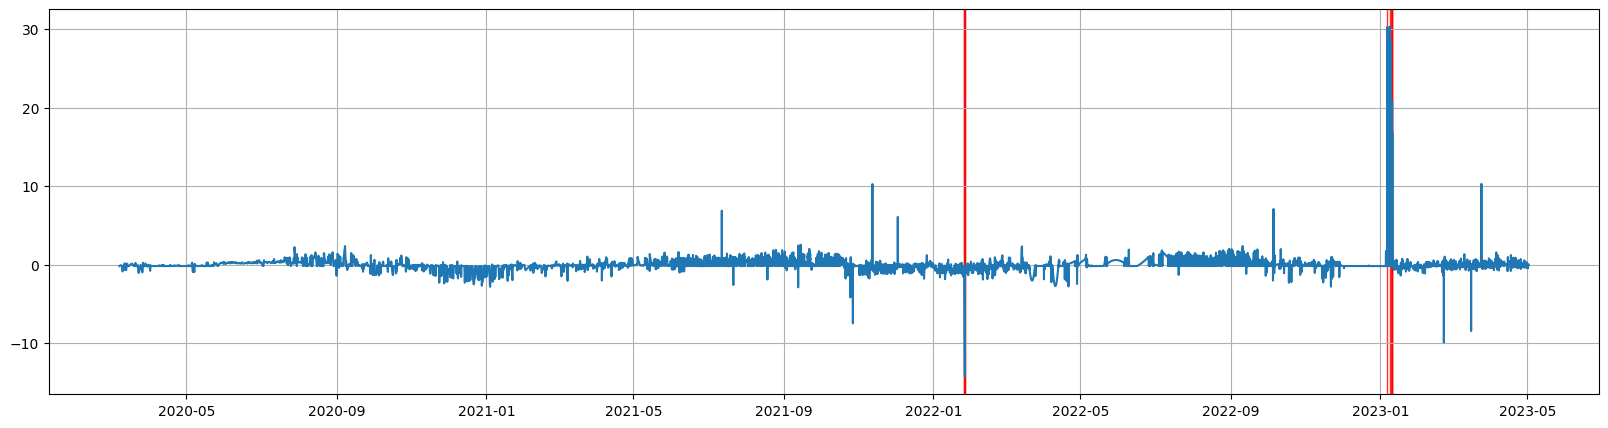

In [97]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(prof1['2020-01-01':'2023-05-01'].index, test)
highlightComaprison(test, pred_outlier_indices, 'red')
plt.grid(True);

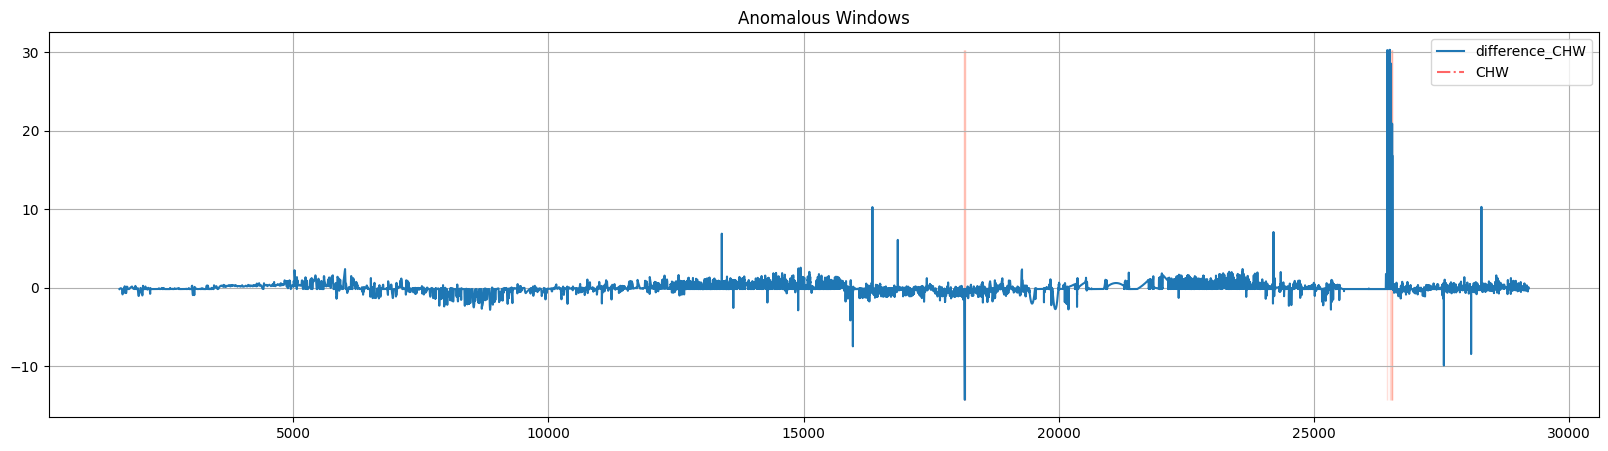

In [98]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(signal_test)
plt.axhline(y=signal_test.mean(), color='r', linestyle='-.', alpha=0.6) # the  horizontal line for mean
plt.axhline(y=signal_test.mean() + signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean + std_dev
plt.axhline(y=signal_test.mean() + 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean + 2 * std_dev
plt.axhline(y=signal_test.mean() - 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean - 2 * std_dev
plt.axhline(y=signal_test.mean() - signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean - std_dev
for w_index in pred_outlier_indices:
    plt.fill_betweenx((np.nanmin(signal_test), np.nanmax(signal_test)), w_index, w_index + intervel_length - 1, alpha=0.2, color='tomato')
plt.title('Anomalous Windows')
plt.legend(["difference_CHW", "CHW"])
plt.grid(True);

In [56]:
### Outlier detection (contain None for spike)

data1 = scaled_df[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]
data1[data1 < -0.1] = None
data1[data1 > 0.1] = None
data1 = data1.fillna(method = "ffill")
data1 = data1.dropna()

# Numerical dataframe
from sklearn.cluster import DBSCAN
model = DBSCAN(eps = 0.001, min_samples = 10).fit(data1)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_62669/3009463891.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data1 = data1.fillna(method = "ffill")


In [35]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2'],
      dtype='object')

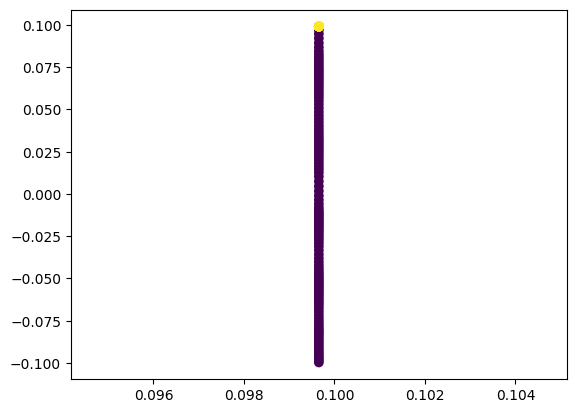

In [38]:
colors = model.labels_
plt.scatter(data1["b084_raw_group2"], data1["b081_raw_group2"], c = colors)

In [39]:
data1[model.labels_ == -1]

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-11-20 19:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.099678
2022-11-20 20:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.098495
2022-11-20 21:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.097326
2022-11-20 22:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.096099
2022-11-20 23:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.094775
...,...,...,...,...,...,...
2022-11-25 13:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.086765
2022-11-25 14:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.089293
2022-11-25 15:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.092072


In [40]:
# GMM 모델 생성
n_clusters = 10  # 클러스터 수를 설정
covariance_type = 'spherical'  # 또는 다른 유형 선택 가능

gmm = GaussianMixture(n_components = n_clusters, covariance_type = covariance_type)
gmm.fit(data1)

# 클러스터 할당
cluster_labels = gmm.predict(data1)

# 결과를 데이터프레임에 추가
data1['Cluster_Label'] = cluster_labels

In [41]:
# Isolation Forest 모델 생성
isolation_forest = IsolationForest(contamination=0.05)  # contamination은 이상치 비율을 나타냅니다

# 모델 훈련
isolation_forest.fit(data1)

# 이상치 여부를 예측 (-1은 이상치, 1은 정상치)
outlier_labels = isolation_forest.predict(data1)

# 결과를 데이터프레임에 추가
data1['Outlier_Label'] = outlier_labels

In [42]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2',
       'Cluster_Label', 'Outlier_Label'],
      dtype='object')

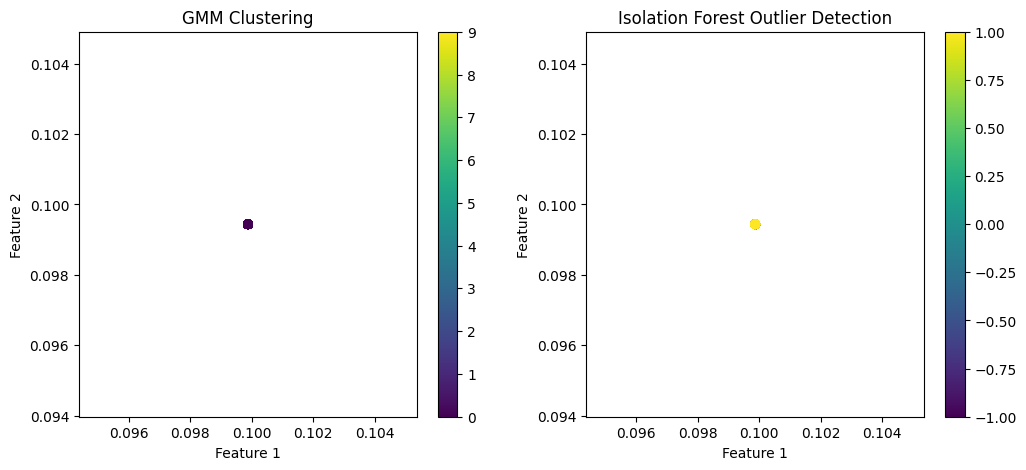

In [44]:
# 클러스터링 결과 및 이상치 시각화
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 클러스터링 결과 시각화
scatter1 = ax1.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=cluster_labels, cmap='viridis')
ax1.set_title("GMM Clustering")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
fig.colorbar(scatter1, ax=ax1)

# 이상치 탐지 결과 시각화
scatter2 = ax2.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=outlier_labels, cmap='viridis')
ax2.set_title("Isolation Forest Outlier Detection")
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
fig.colorbar(scatter2, ax=ax2)

plt.show()

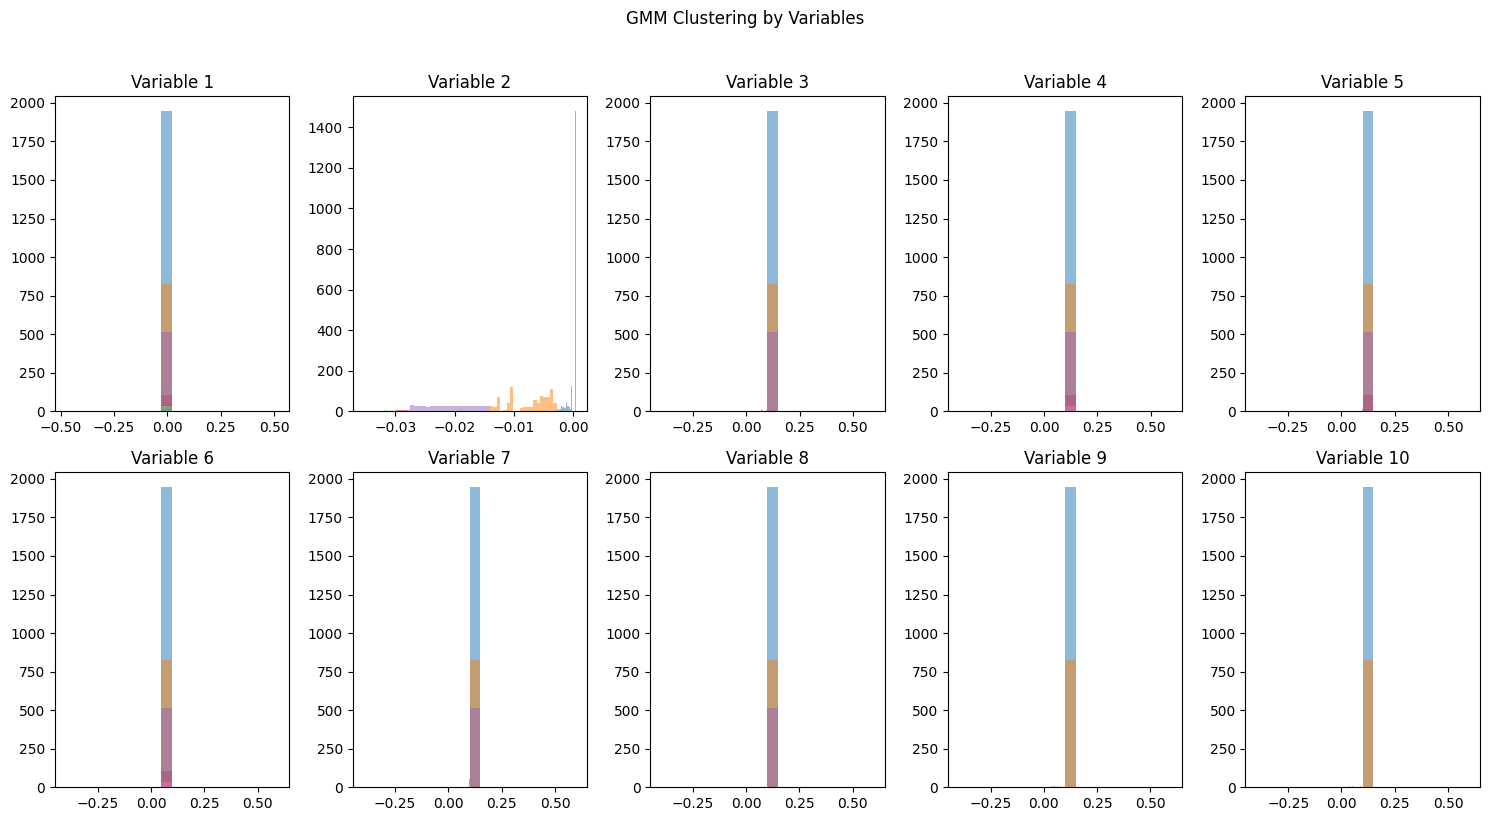

In [103]:
# 클러스터링 결과 시각화
plt.figure(figsize=(15, 8))
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    for i in range(10):  # 10개 변수
        plt.subplot(2, 5, i + 1)
        plt.hist(cluster_data.iloc[:, i], bins = 20, alpha = 0.5, label = f'Cluster {cluster_label + 1}')
        plt.title(f'Variable {i + 1}')
    
plt.suptitle("GMM Clustering by Variables", y = 1.02)
plt.tight_layout()
plt.show()

In [105]:
cluster_data

,b181_raw_group1,b146_raw_group1,b153_raw_group1,b147_raw_group1,b165_raw_group1,b167_raw_group1,b195_raw_group1,b790_raw_group1,b116_raw_group1,b064_raw_group1,Cluster_Label,Outlier_Label
Date/Time,,,,,,,,,,,,
2022-10-11 22:00:00,0.021912,-0.002759,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-11 23:00:00,0.021912,-0.002746,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 00:00:00,0.021912,-0.002732,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 01:00:00,0.021912,-0.002716,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 02:00:00,0.021912,-0.002699,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-31 18:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 19:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 20:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1


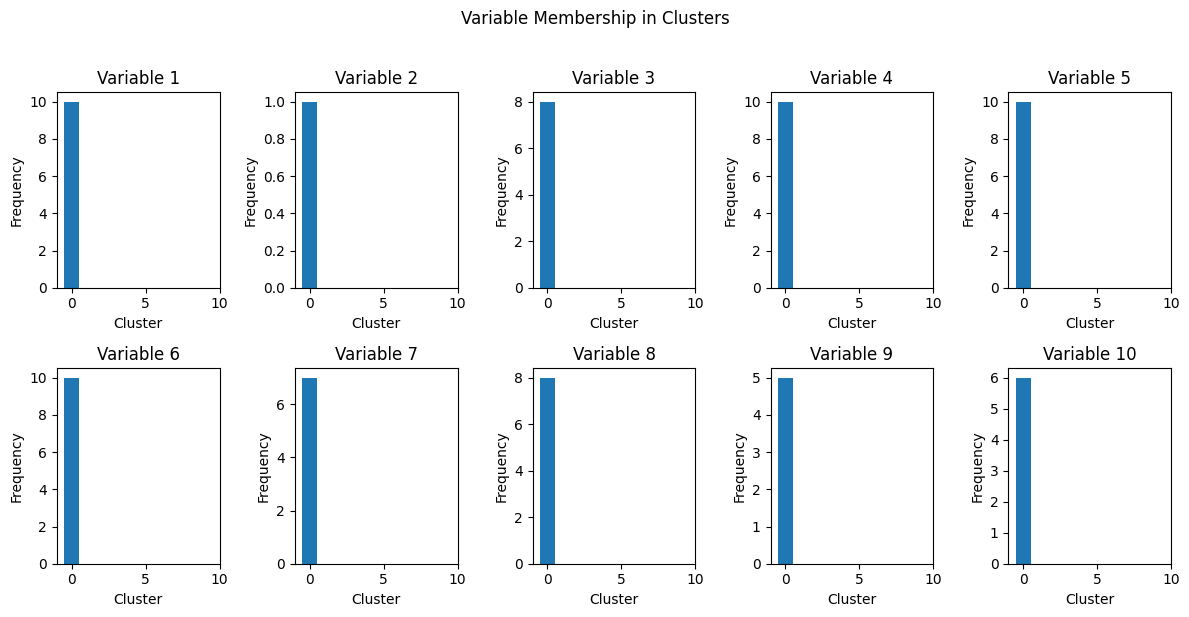

In [107]:
import numpy as np

# 각 변수의 클러스터 소속 확인
variable_cluster_labels = np.zeros((10, n_clusters))  # 변수의 개수 x 클러스터 수
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    cluster_data = cluster_data.drop(['Cluster_Label', "Outlier_Label"], axis = 1)
    variable_cluster_labels[:, cluster_label] = np.mean(cluster_data, axis=0)


# 변수별 클러스터 소속 시각화
plt.figure(figsize=(12, 6))
for i in range(10):  # 10개 변수
    plt.subplot(2, 5, i + 1)
    counts, bins, _ = plt.hist(variable_cluster_labels[i], bins=range(n_clusters + 1), align='left')
    plt.title(f'Variable {i + 1}')
    plt.xlabel('Cluster')
    plt.ylabel('Frequency')
    
plt.suptitle("Variable Membership in Clusters", y=1.02)
plt.tight_layout()
plt.show()


### Generate NAN and Impute GAN (pilot)

In [79]:
data1 = data1.reset_index()
# data1 = data1.drop(['Index'], axis = 1)

In [ ]:
# 결측값 생성

num_points = len(data1)
num_variables = 6
missing_rate = 0.2
for column in df.columns:
    num_missing = int(num_points * missing_rate)
    missing_indices = np.random.choice(num_points, num_missing, replace=False)
    data1.loc[missing_indices, column] = np.nan

In [87]:
data1.index = data1["Date/Time"]
data1 = data1.drop(['Date/Time', "index"], axis = 1)

# Extract data with pt
filtered_columns = [col for col in data1.columns if "raw" in col]

# 선택한 변수를 새로운 데이터 프레임으로 추출
data1 = data1[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]

In [111]:
from tensorflow import keras
import torch
import torch.nn as nn
import torch.optim as optim

In [88]:
data1.head()

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-04-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-01 01:00:00,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2022-04-01 02:00:00,0.0,0.000058,0.000281,NaN,NaN,NaN
2022-04-01 03:00:00,0.0,0.000035,0.000268,0.000308,NaN,NaN
2022-04-01 04:00:00,0.0,NaN,NaN,0.000298,NaN,NaN


In [91]:
data1 = data1.reset_index()
data1 = data1.drop(['Date/Time'], axis = 1)

In [93]:
data1

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2,0.0,0.000058,0.000281,NaN,NaN,NaN
3,0.0,0.000035,0.000268,0.000308,NaN,NaN
4,0.0,NaN,NaN,0.000298,NaN,NaN
...,...,...,...,...,...,...
6594,0.0,0.000035,0.000287,NaN,0.000000,0.000426
6595,0.0,NaN,NaN,0.000286,NaN,NaN
6596,0.0,NaN,0.000265,0.000288,0.000012,0.000416
6597,NaN,NaN,0.000216,NaN,0.000000,0.000435


In [116]:
# 데이터프레임을 PyTorch 텐서로 변환
real_data = torch.FloatTensor(data1.dropna().values)

In [122]:
# Generator 모델 정의
class Generator(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(Generator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, output_dim),
            nn.Tanh()
        )

    def forward(self, x):
        return self.fc(x)

# Discriminator 모델 정의
class Discriminator(nn.Module):
    def __init__(self, input_dim):
        super(Discriminator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.fc(x)

In [128]:
# Generator와 Discriminator 모델 초기화
input_dim = 32
output_dim = num_variables
generator = Generator(input_dim, output_dim)
discriminator = Discriminator(output_dim)

# 손실 함수 및 옵티마이저 정의
criterion = nn.BCELoss()
optimizer_g = optim.Adam(generator.parameters(), lr=0.0002)
optimizer_d = optim.Adam(discriminator.parameters(), lr=0.0002)

In [134]:
# GAN 모델 훈련
num_epochs = 100
batch_size = 32

for epoch in range(num_epochs):
    num_batches = real_data.shape[0] // batch_size
    for _ in range(num_batches):
        noise = torch.randn(batch_size, input_dim)
        generated_data = generator(noise)
        real_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        fake_labels = torch.zeros((batch_size, 1), dtype=torch.float32)

        # Discriminator 훈련
        optimizer_d.zero_grad()
        real_output = discriminator(real_data[:batch_size])
        fake_output = discriminator(generated_data)
        discriminator_loss_real = criterion(real_output, real_labels)
        discriminator_loss_fake = criterion(fake_output, fake_labels)
        discriminator_loss = discriminator_loss_real + discriminator_loss_fake
        discriminator_loss.backward(retain_graph=True)
        optimizer_d.step()

        # Generator를 통한 GAN 훈련
        optimizer_g.zero_grad()
        gan_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        gan_output = discriminator(generated_data)
        gan_loss = criterion(gan_output, gan_labels)
        gan_loss.backward()
        optimizer_g.step()

    print(f'Epoch {epoch}, D Loss: {discriminator_loss.item()}, G Loss: {gan_loss.item()}')


Epoch 0, D Loss: 1.3854780197143555, G Loss: 0.6327202320098877
Epoch 1, D Loss: 1.3908488750457764, G Loss: 0.6290866136550903
Epoch 2, D Loss: 1.3863091468811035, G Loss: 0.6368914246559143
Epoch 3, D Loss: 1.3897672891616821, G Loss: 0.6354539394378662
Epoch 4, D Loss: 1.3817918300628662, G Loss: 0.6448863744735718
Epoch 5, D Loss: 1.3989853858947754, G Loss: 0.6333292722702026
Epoch 6, D Loss: 1.372666358947754, G Loss: 0.6603043675422668
Epoch 7, D Loss: 1.3731648921966553, G Loss: 0.6610397100448608
Epoch 8, D Loss: 1.3767998218536377, G Loss: 0.6590506434440613
Epoch 9, D Loss: 1.3822531700134277, G Loss: 0.6567761898040771
Epoch 10, D Loss: 1.379887342453003, G Loss: 0.6593412160873413
Epoch 11, D Loss: 1.3736572265625, G Loss: 0.6676796078681946
Epoch 12, D Loss: 1.3731087446212769, G Loss: 0.6703320145606995
Epoch 13, D Loss: 1.3778290748596191, G Loss: 0.6668186783790588
Epoch 14, D Loss: 1.3695826530456543, G Loss: 0.6758610606193542
Epoch 15, D Loss: 1.371976613998413, G L

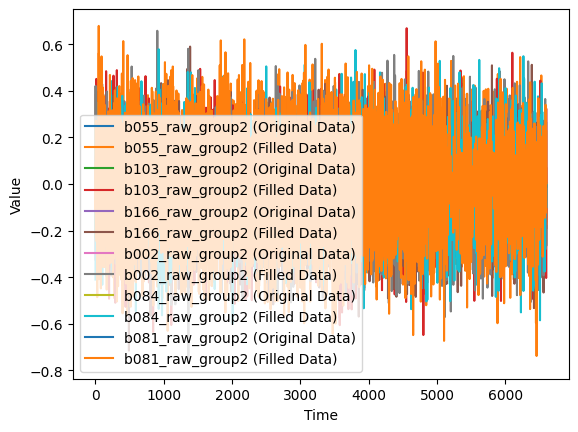

In [136]:
# 결측값을 GAN을 사용하여 채우기
missing_data = data1.copy()
for column in missing_data.columns:
    missing_indices = missing_data[column].isna()
    num_missing = missing_indices.sum()
    noise = torch.randn(num_missing, input_dim)
    generated_values = generator(noise).detach().numpy()
    missing_data.loc[missing_indices, column] = generated_values.flatten()[:num_missing]

# 결과를 시각화
for column in data1.columns:
    plt.plot(data1[column], label=f'{column} (Original Data)')
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

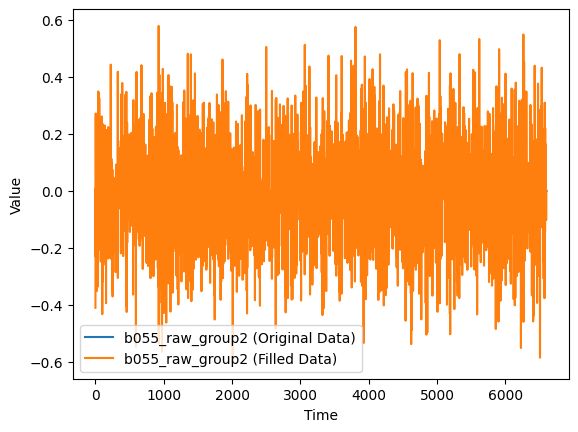

In [148]:
# 결과를 시각화

plt.plot(data1["b084_raw_group2"], label=f'{column} (Original Data)')
plt.plot(missing_data["b084_raw_group2"], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

ValueError: x and y must be the same size

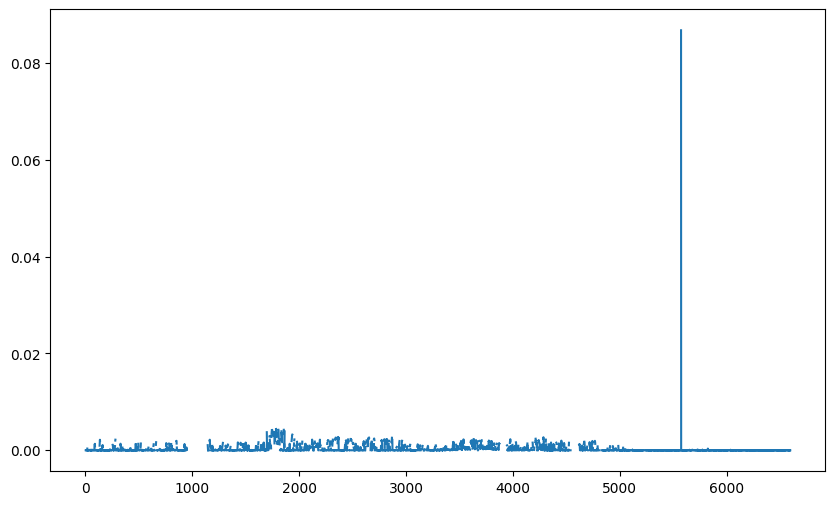

In [141]:
# 결과를 시각화
for column in data1.columns:
    plt.figure(figsize=(10, 6))
    plt.plot(data1[column], label=f'{column} (Original Data)')
    
    # 결측값인 지점에 동그라미 표시
    missing_indices = data1[column].isna()
    plt.scatter(missing_indices.index, data1[column][missing_indices], c='r', marker='o', label='Missing Data')
    
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
    
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.show()